In [1]:
# Imports
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import torch

from pathlib import Path
from tqdm.auto import tqdm

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# Dataset paths
DATA_DIR = Path("/kaggle/input")
VIDEO_DIR = DATA_DIR / "ravdess-emotional-speech-video" / "RAVDESS dataset"
CSV_DIR = DATA_DIR / "ravdess-facial-tracking"
OUTPUT_DIR = Path("/kaggle/working/ravdess_multimodal")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Label mappings
EMOTIONS = {
    1: "Neutral", 2: "Calm", 3: "Happy", 4: "Sad",
    5: "Angry", 6: "Fearful", 7: "Disgust", 8: "Surprised"
}

INTENSITY = {1: "Normal", 2: "Strong"}
CHANNEL = {1: "Speech", 2: "Song"}

# Audio configuration
SAMPLE_RATE = 22050
N_MFCC = 40

print("Setup complete!")

Device: cuda
Setup complete!


In [2]:
# ============================================
# CELL 2: DATASET INVENTORY
# ============================================

LABELS = ["modality", "channel", "emotion", "intensity",
          "statement", "repetition", "actor"]

# Find files
video_files = list(VIDEO_DIR.rglob("*.mp4"))
csv_files = list(CSV_DIR.rglob("*.csv"))

# Extract metadata
def build_df(files, path_col):
    rows = []
    for f in files:
        parts = f.stem.split("-")
        if len(parts) == 7 and all(p.isdigit() for p in parts):
            rows.append({
                "filename": f.stem,
                **dict(zip(LABELS, map(int, parts))),
                path_col: str(f)
            })
    return pd.DataFrame(rows)

video_df = build_df(video_files, "video_path")
face_df = build_df(csv_files, "csv_path")

# Pair audio-video samples with facial CSVs
av_df = video_df[video_df.modality == 1].merge(
    face_df[["filename", "csv_path"]],
    on="filename",
    how="inner"
)

print(f"Videos: {len(video_df)}")
print(f"Facial CSVs: {len(face_df)}")
print(f"Audio-video samples: {(video_df.modality == 1).sum()}")
print(f"Successfully paired: {len(av_df)}")

display(av_df.head())

Videos: 2880
Facial CSVs: 2452
Audio-video samples: 1440
Successfully paired: 1440


,filename,modality,channel,emotion,intensity,statement,repetition,actor,video_path,csv_path
0,01-01-01-01-01-01-01,1,1,1,1,1,1,1,/kaggle/input/ravdess-emotional-speech-video/R...,/kaggle/input/ravdess-facial-tracking/01-01-01...
1,01-01-01-01-01-02-01,1,1,1,1,1,2,1,/kaggle/input/ravdess-emotional-speech-video/R...,/kaggle/input/ravdess-facial-tracking/01-01-01...
2,01-01-01-01-02-01-01,1,1,1,1,2,1,1,/kaggle/input/ravdess-emotional-speech-video/R...,/kaggle/input/ravdess-facial-tracking/01-01-01...
3,01-01-01-01-02-02-01,1,1,1,1,2,2,1,/kaggle/input/ravdess-emotional-speech-video/R...,/kaggle/input/ravdess-facial-tracking/01-01-01...
4,01-01-02-01-01-01-01,1,1,2,1,1,1,1,/kaggle/input/ravdess-emotional-speech-video/R...,/kaggle/input/ravdess-facial-tracking/01-01-02...


In [3]:
# ============================================
# CELL 3: FACIAL DATA INSPECTION
# ============================================

sample = pd.read_csv(av_df.iloc[0]["csv_path"])

print("Shape:", sample.shape)
print("Missing values:", sample.isna().sum().sum())
print("Average tracking confidence:", sample["confidence"].mean())

display(sample.head(3))

Shape: (98, 712)
Missing values: 0
Average tracking confidence: 0.9800000000000002


,frame,timestamp,confidence,gaze_0_x,gaze_0_y,gaze_0_z,gaze_1_x,gaze_1_y,gaze_1_z,gaze_angle_x,...,AU12_c,AU14_c,AU15_c,AU17_c,AU20_c,AU23_c,AU25_c,AU26_c,AU28_c,AU45_c
0,1,0.000,0.98,0.068407,0.337437,-0.938859,-0.130211,0.294125,-0.946856,-0.033,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
1,2,0.033,0.98,0.170199,0.301091,-0.938284,-0.077985,0.228398,-0.970440,0.048,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,3,0.067,0.98,0.169057,0.236200,-0.956885,-0.106635,0.242925,-0.964166,0.032,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


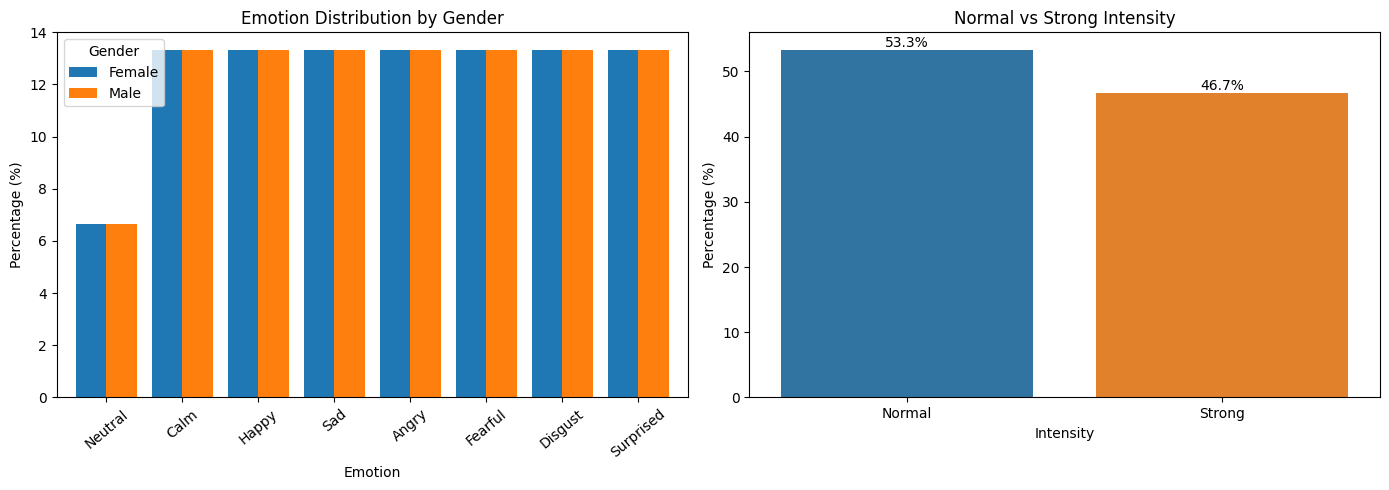

In [4]:
# ============================================
# CELL 4: EMOTION & INTENSITY DISTRIBUTION
# ============================================

eda = av_df.copy()

eda["Emotion"] = eda["emotion"].map(EMOTIONS)
eda["Gender"] = np.where(eda["actor"] % 2 == 1, "Male", "Female")
eda["Intensity"] = eda["intensity"].map(INTENSITY)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Emotion distribution by gender (%)
gender_emotion = pd.crosstab(
    eda["Emotion"], eda["Gender"], normalize="columns"
) * 100

gender_emotion.reindex(list(EMOTIONS.values())).plot(
    kind="bar", ax=axes[0], width=0.8
)

axes[0].set_title("Emotion Distribution by Gender")
axes[0].set_ylabel("Percentage (%)")
axes[0].set_xlabel("Emotion")
axes[0].tick_params(axis="x", rotation=40)
axes[0].legend(title="Gender")

# 2. Normal vs Strong intensity (%)
intensity_pct = eda["Intensity"].value_counts(normalize=True) * 100

sns.barplot(
    x=intensity_pct.index,
    y=intensity_pct.values,
    order=["Normal", "Strong"],
    ax=axes[1]
)

axes[1].set_title("Normal vs Strong Intensity")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xlabel("Intensity")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()

In [5]:
features = []

for _, row in tqdm(av_df.iterrows(), total=len(av_df),
                   desc="Reading all facial CSV columns"):

    df = pd.read_csv(row["csv_path"])

    result = {
        "filename": row["filename"],
        "emotion": row["emotion"],
        "intensity": row["intensity"],
        "actor": row["actor"],
        "duration": df["timestamp"].max() - df["timestamp"].min(),
        "n_frames": len(df),
        "confidence": df["confidence"].mean()
    }

    # Read and summarize every numeric column
    numeric_df = df.select_dtypes(include=np.number)

    for col in numeric_df.columns:
        result[f"{col}_mean"] = numeric_df[col].mean()
        result[f"{col}_std"] = numeric_df[col].std()
        result[f"{col}_min"] = numeric_df[col].min()
        result[f"{col}_max"] = numeric_df[col].max()

    features.append(result)

facial_features_df = pd.DataFrame(features)

print("Samples:", len(facial_features_df))
print("Extracted features:", len(facial_features_df.columns))
display(facial_features_df.head())

Reading all facial CSV columns:   0%|          | 0/1440 [00:00<?, ?it/s]

Samples: 1440
Extracted features: 2855


,filename,emotion,intensity,actor,duration,n_frames,confidence,frame_mean,frame_std,frame_min,...,AU26_c_min,AU26_c_max,AU28_c_mean,AU28_c_std,AU28_c_min,AU28_c_max,AU45_c_mean,AU45_c_std,AU45_c_min,AU45_c_max
0,01-01-01-01-01-01-01,1,1,1,3.237,98,0.98,49.5,28.434134,1,...,0.0,1.0,0.000000,0.000000,0.0,0.0,0.448980,0.499947,0.0,1.0
1,01-01-01-01-01-02-01,1,1,1,3.270,99,0.98,50.0,28.722813,1,...,0.0,1.0,0.000000,0.000000,0.0,0.0,0.777778,0.417855,0.0,1.0
2,01-01-01-01-02-01-01,1,1,1,3.203,97,0.98,49.0,28.145456,1,...,1.0,1.0,0.216495,0.413995,0.0,1.0,0.762887,0.427522,0.0,1.0
3,01-01-01-01-02-02-01,1,1,1,3.103,94,0.98,47.5,27.279418,1,...,1.0,1.0,0.255319,0.438378,0.0,1.0,0.829787,0.377835,0.0,1.0
4,01-01-02-01-01-01-01,2,1,1,3.470,105,0.98,53.0,30.454885,1,...,0.0,1.0,0.000000,0.000000,0.0,0.0,0.809524,0.394560,0.0,1.0


In [6]:
feature_cols = facial_features_df.select_dtypes(include=np.number).columns

print("Dataset shape:", facial_features_df.shape)
print("Missing values:", facial_features_df[feature_cols].isna().sum().sum())
print("Constant features:", (facial_features_df[feature_cols].nunique() <= 1).sum())

Dataset shape: (1440, 2855)
Missing values: 0
Constant features: 5



GRAPH 1: Facial Action Intensity Heatmap
Measures: Mean intensity of each facial action by emotion.
Look for: Happy: smile and cheek raising. Disgust: nose wrinkling and upper-lip raising.


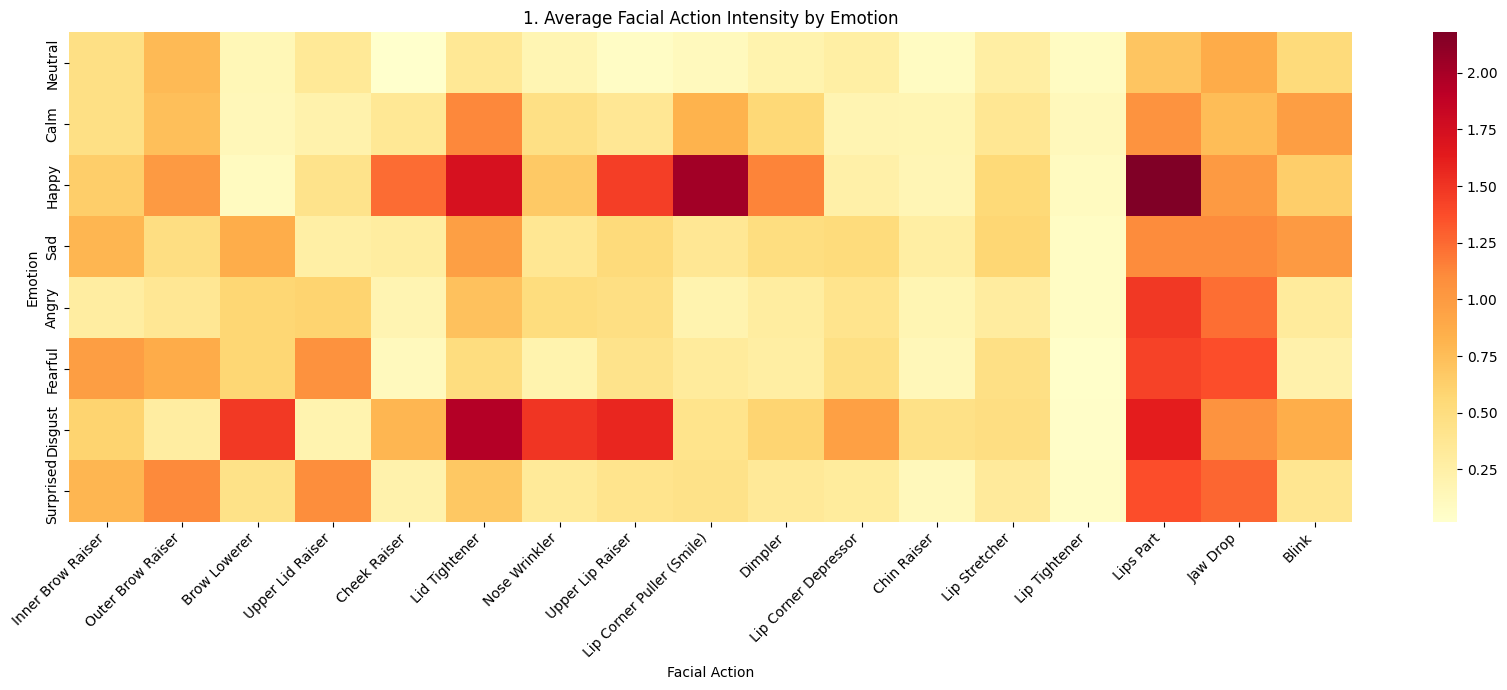


GRAPH 2: Facial Action Activation Frequency
Measures: Percentage of video frames containing each facial action.
Look for: Happy may show frequent smiling; disgust may show frequent nose wrinkling.


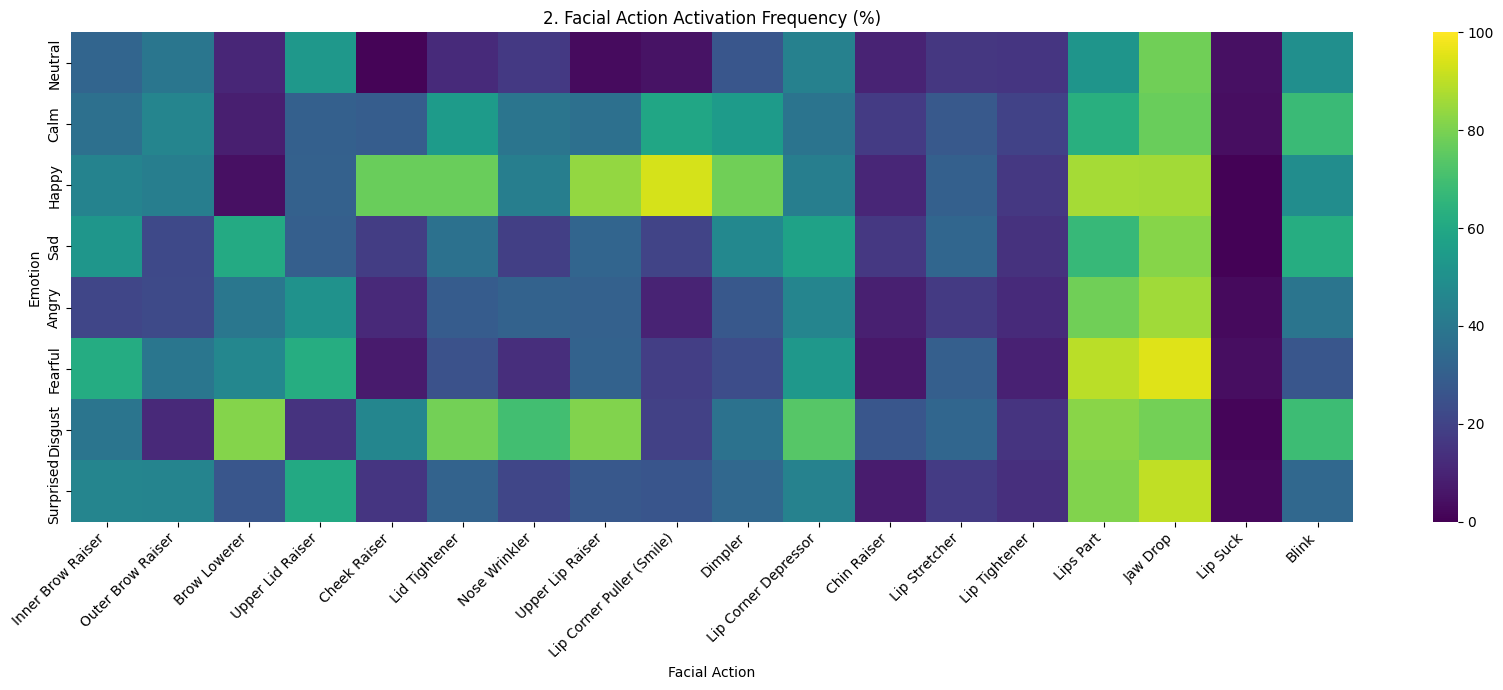


GRAPH 3: Facial Action Correlation
Measures: Relationships between facial action intensities.
Look for: Cheek raising and smiling may correlate; brow lowering and eyelid tightening may correlate.


/usr/local/lib/python3.10/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


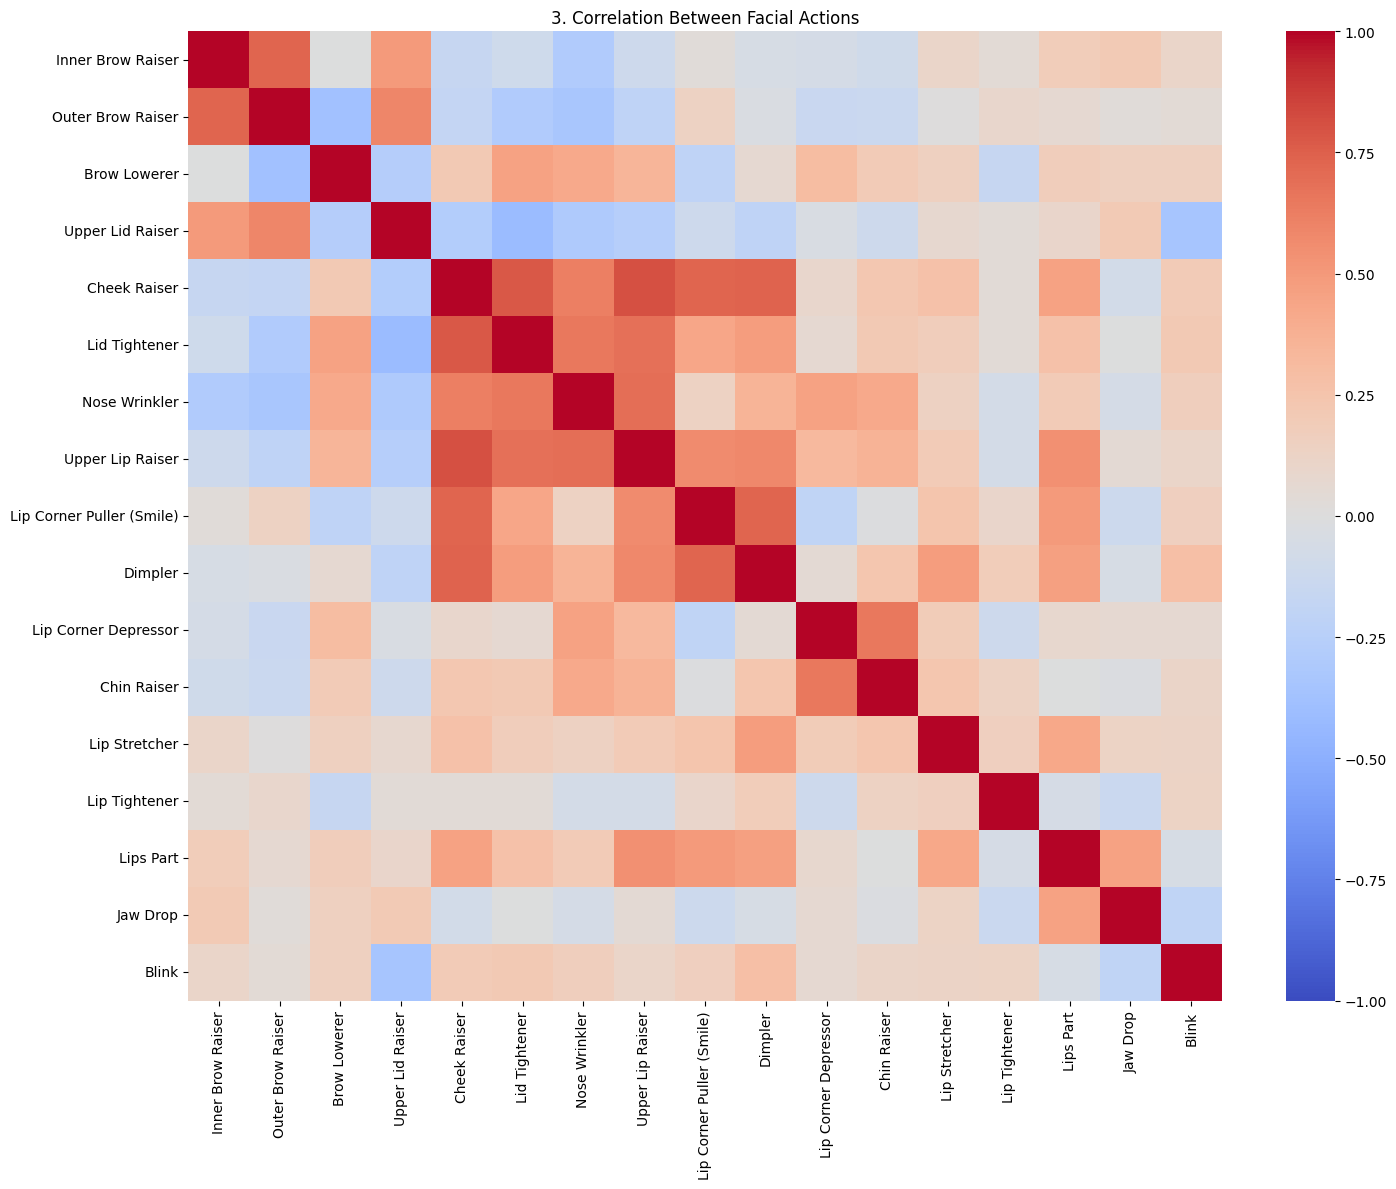


GRAPH 4: Normal vs Strong Facial Expressions
Measures: Facial action intensity for normal and strong expressions.
Look for: Strong expressions may show higher intensity in some facial actions.


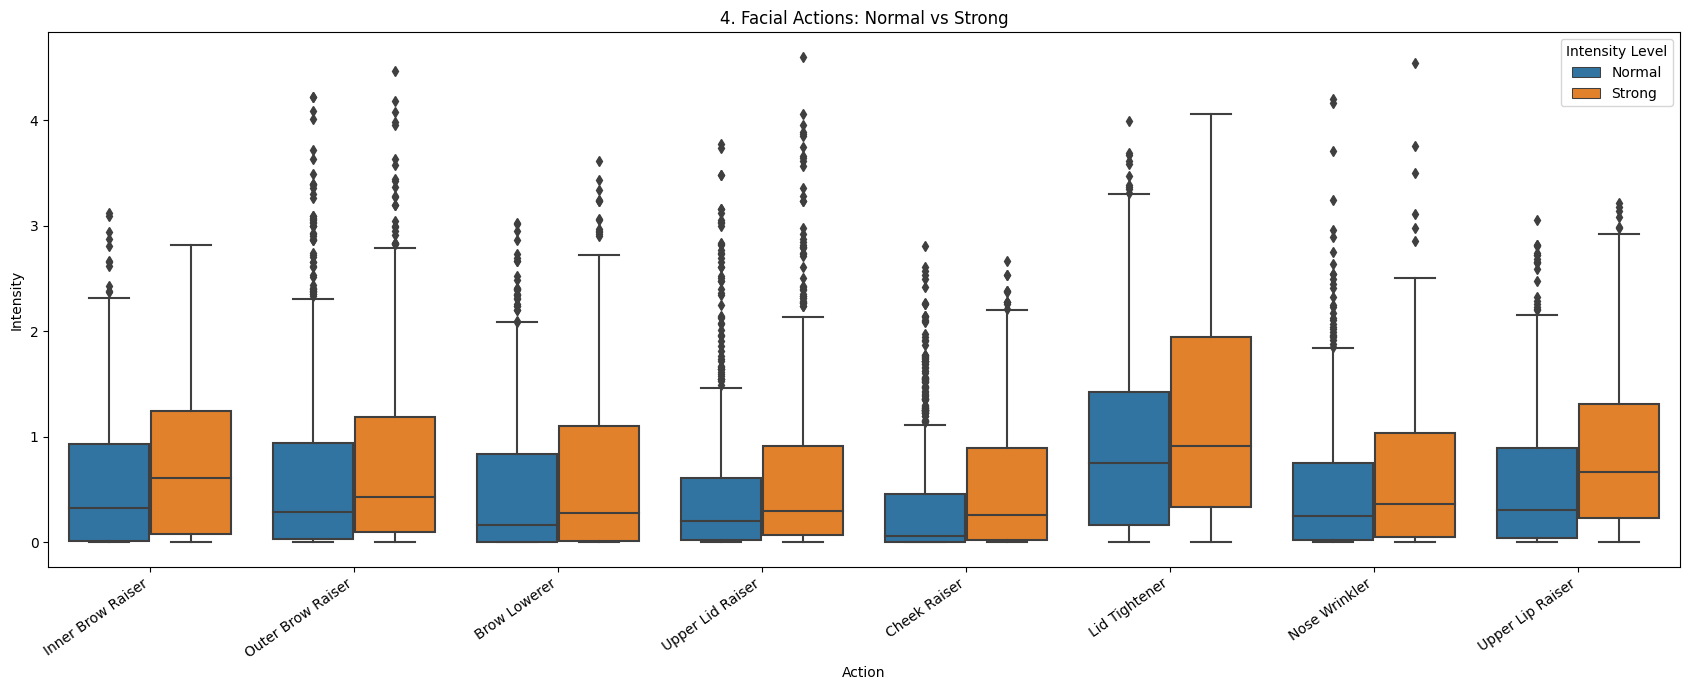


GRAPH 5: Facial Action Radar Profiles
Measures: Average facial action profile of each emotion.
Look for: Look for distinct shapes; smiling actions may distinguish Happy.


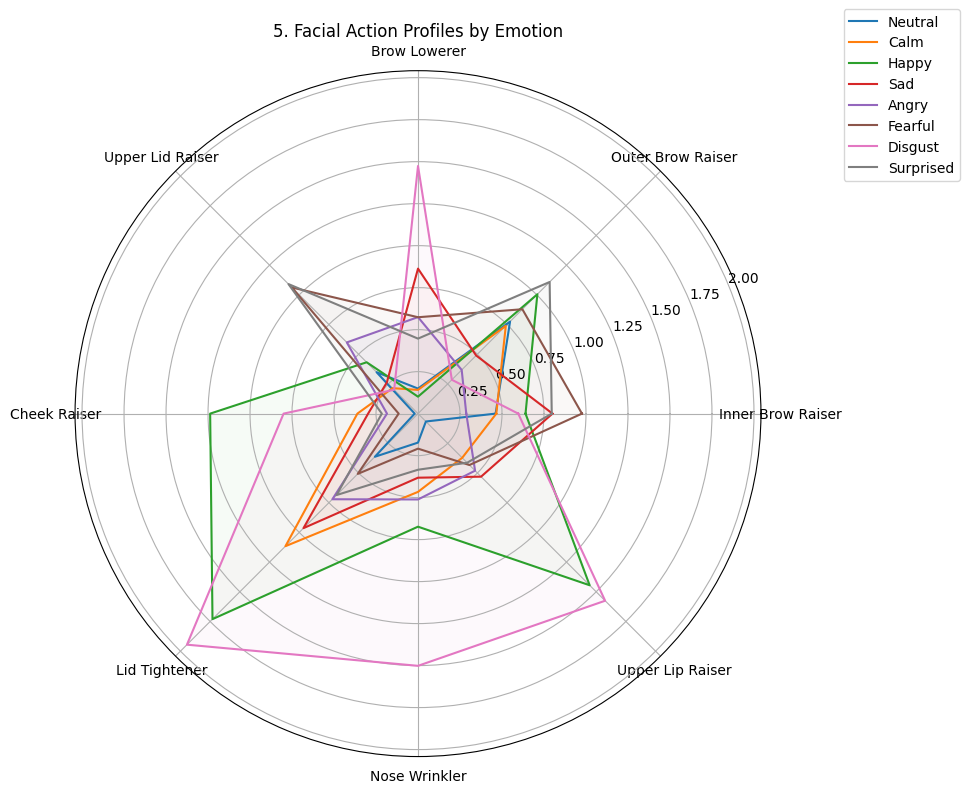


GRAPH 6: Facial Action Evolution Over Time
Measures: Changes in facial action intensity throughout one video per emotion.
Look for: Look for expression onset, intensity peaks, and relaxation.


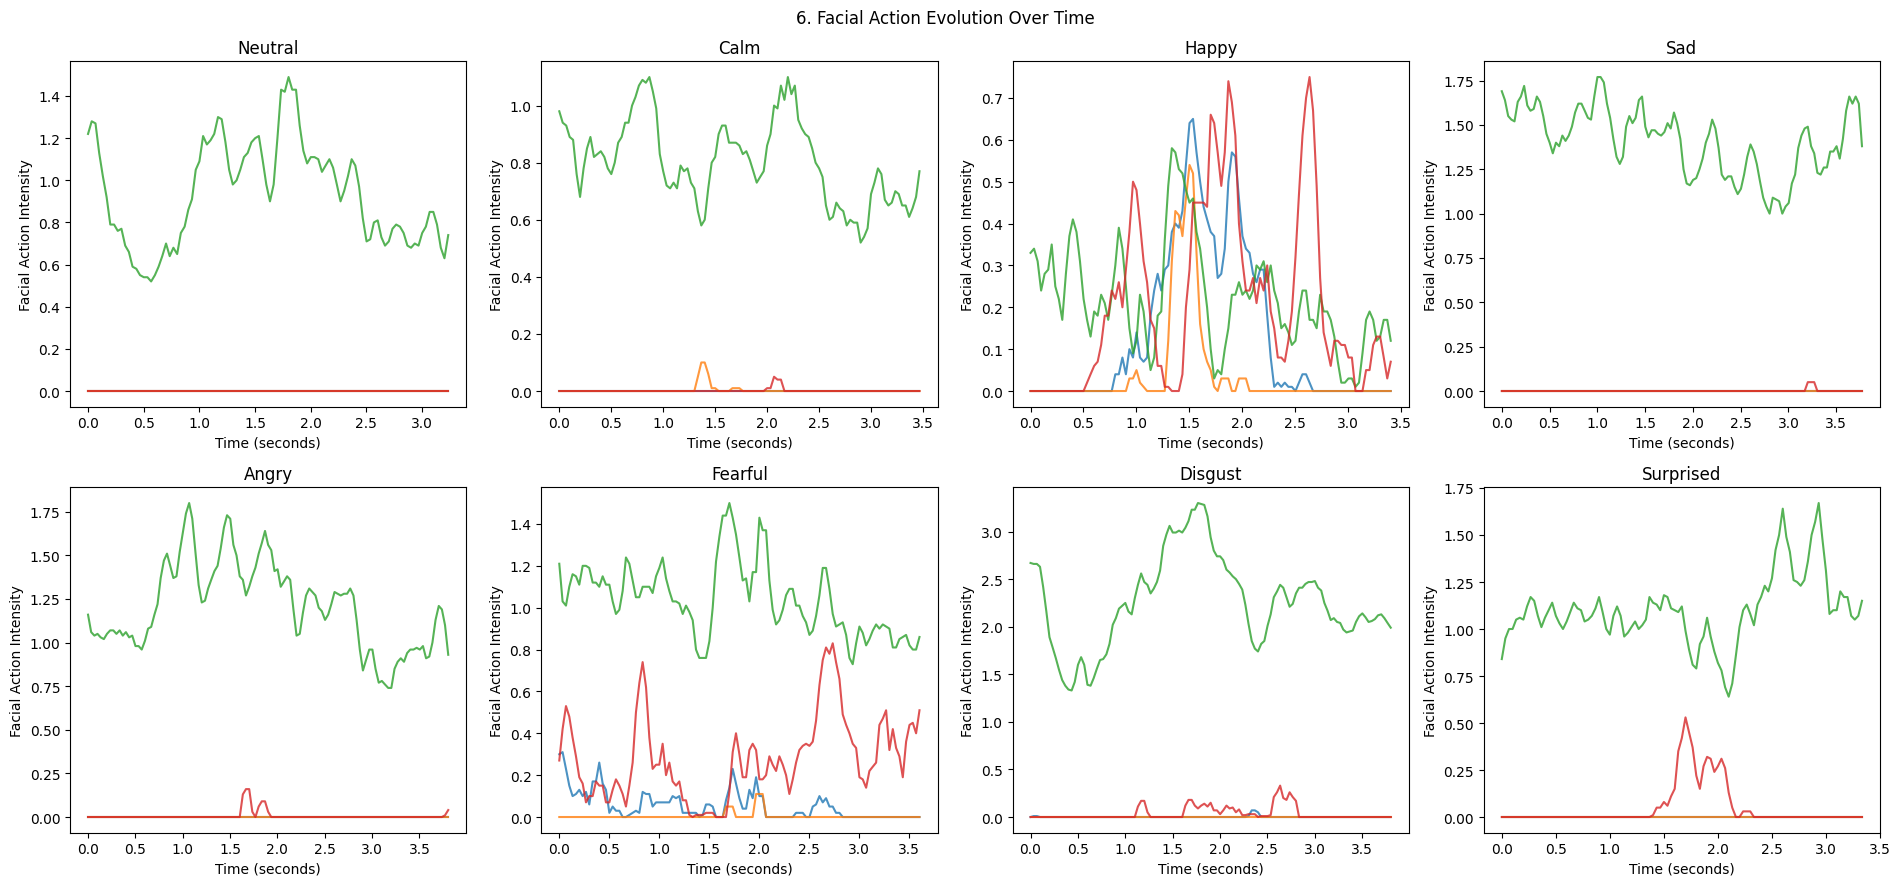


GRAPH 7: Gaze Direction Components
Measures: Average X, Y and Z gaze-vector components for both eyes.
Look for: Look for differences in gaze direction and variation across emotions.


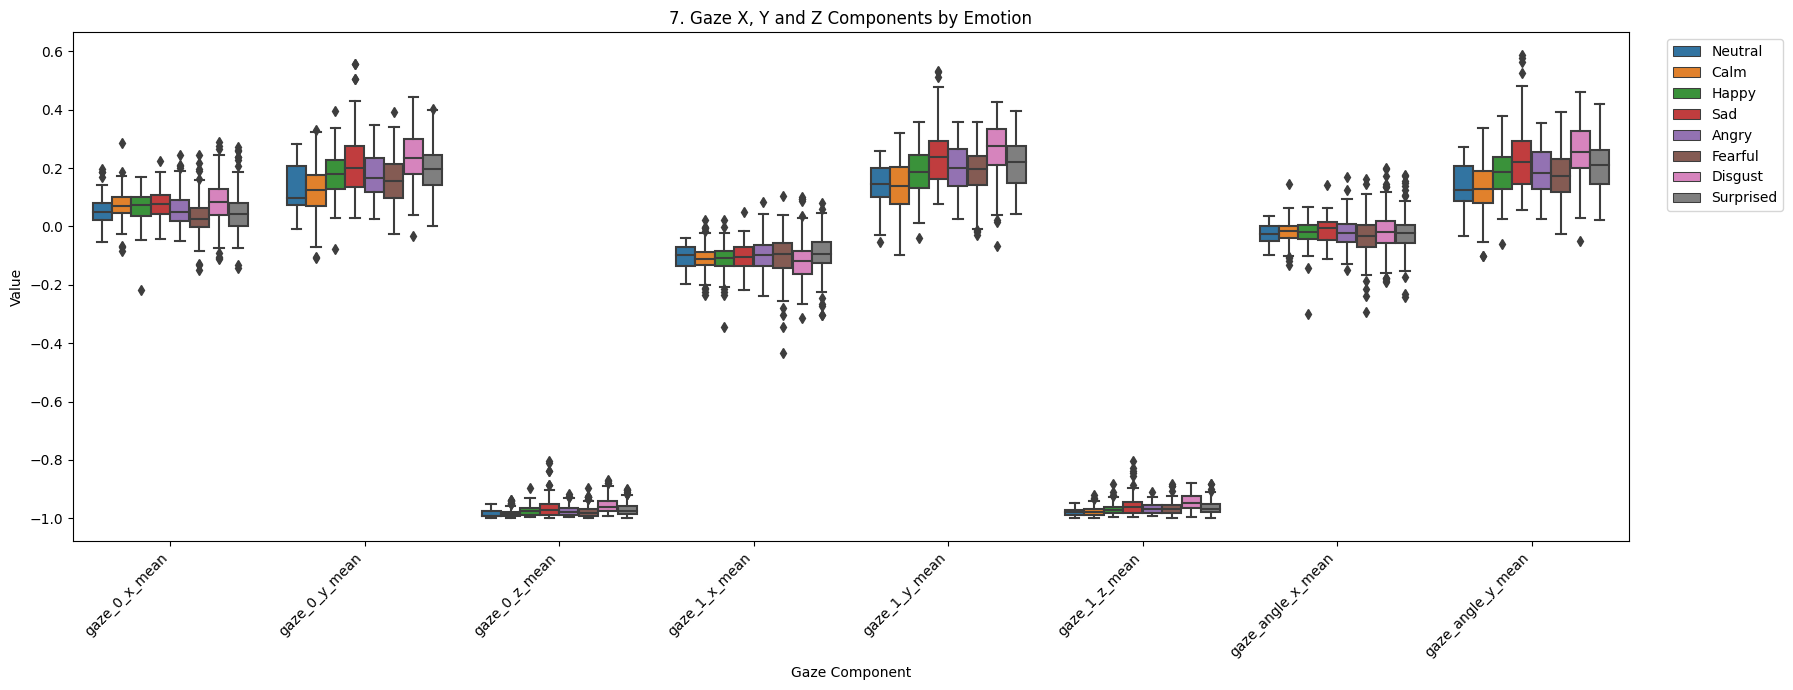


GRAPH 8: Gaze Direction Over Time
Measures: Left and right eye gaze direction throughout a recording.
Look for: Look for gaze shifts, stability, and differences between the eyes.


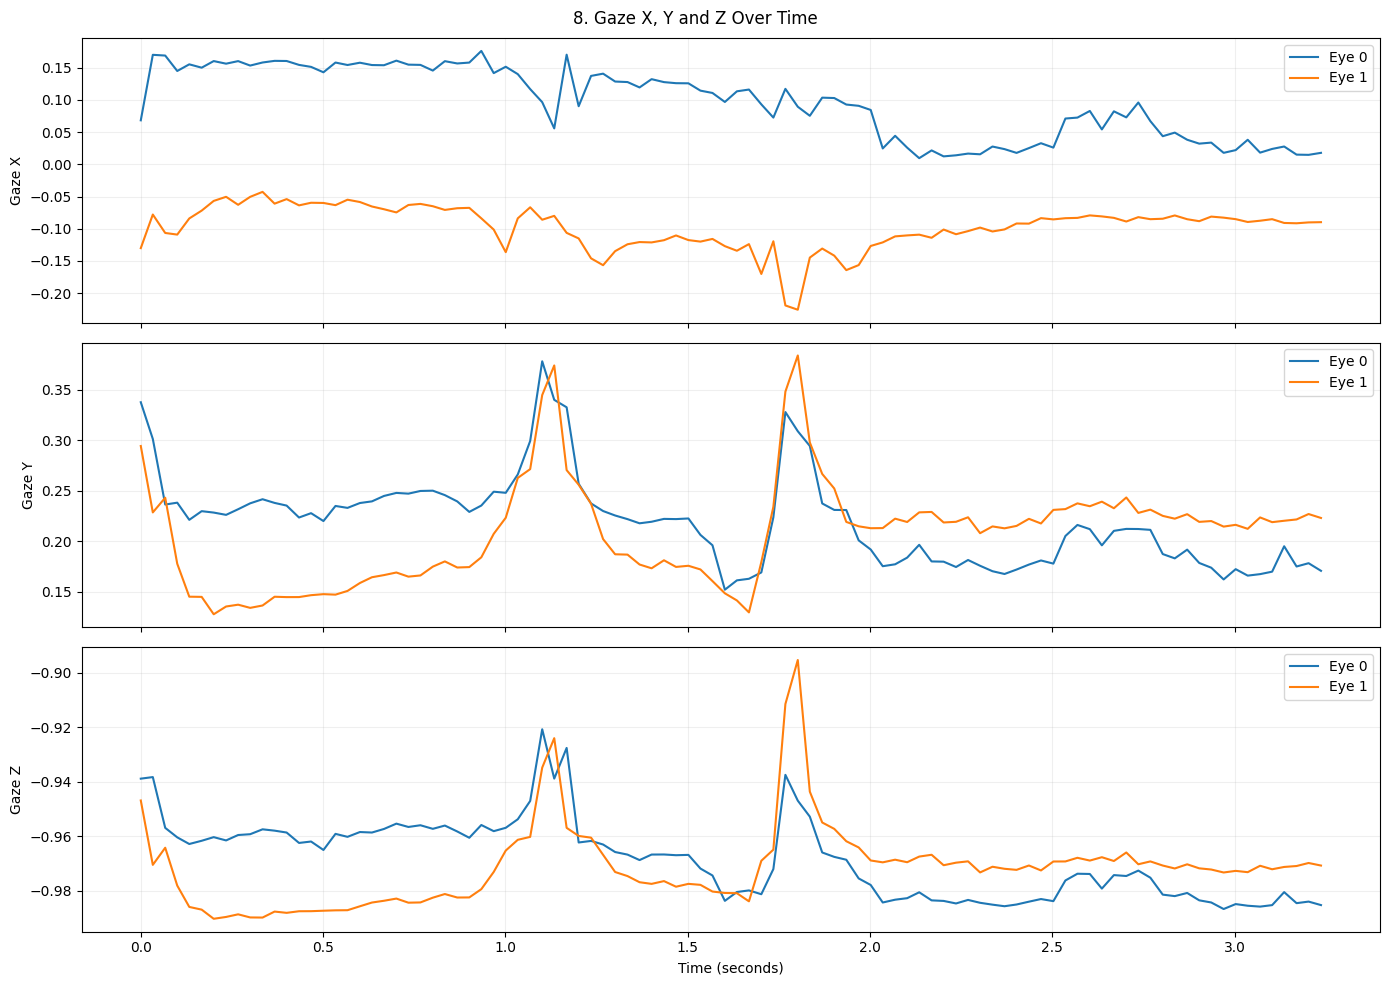


GRAPH 9: Happy vs Angry Average Facial Landmarks
Measures: Average positions of 68 facial landmarks across all recordings.
Look for: Compare the average positions of the eyes, eyebrows, nose, and mouth.


Processing Happy:   0%|          | 0/192 [00:00<?, ?it/s]

Processing Angry:   0%|          | 0/192 [00:00<?, ?it/s]

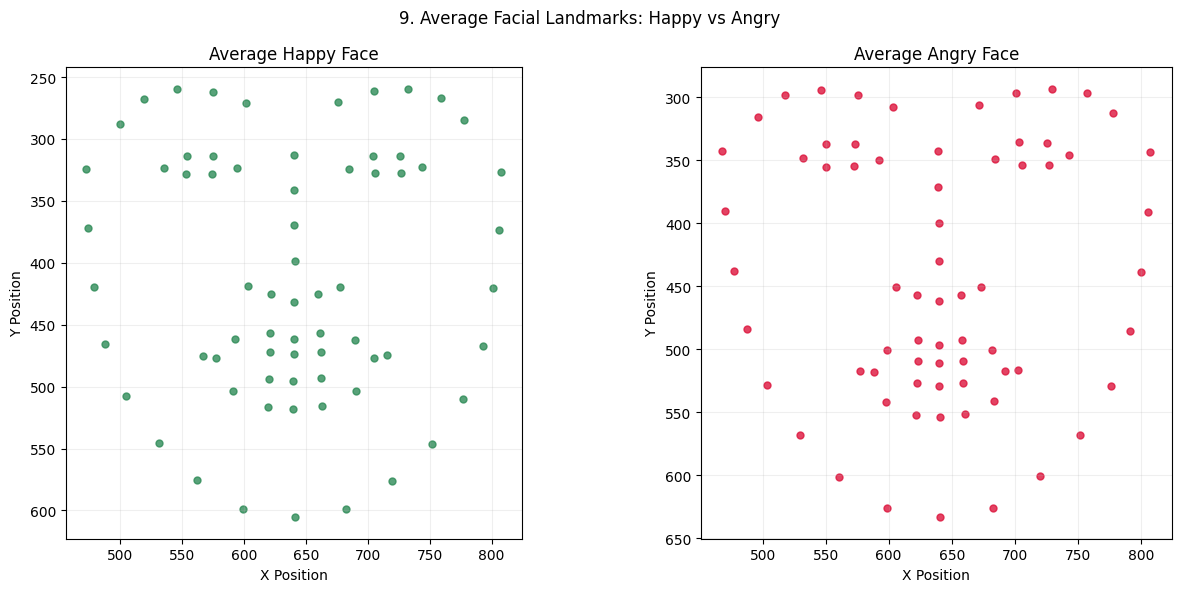


GRAPH 10: Facial Tracking Confidence
Measures: Average OpenFace tracking confidence per recording.
Look for: Confidence should ideally remain high across all emotions.


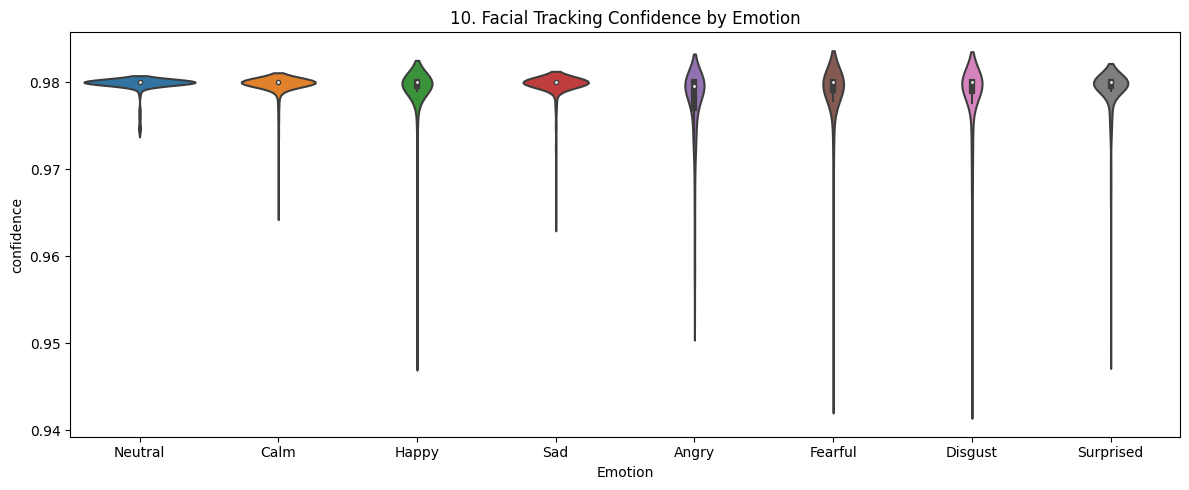


GRAPH 11: t-SNE of Facial Actions
Measures: Nonlinear 2D representation of facial action features.
Look for: Look for emotion groupings and overlap, without treating clusters as proof of accuracy.


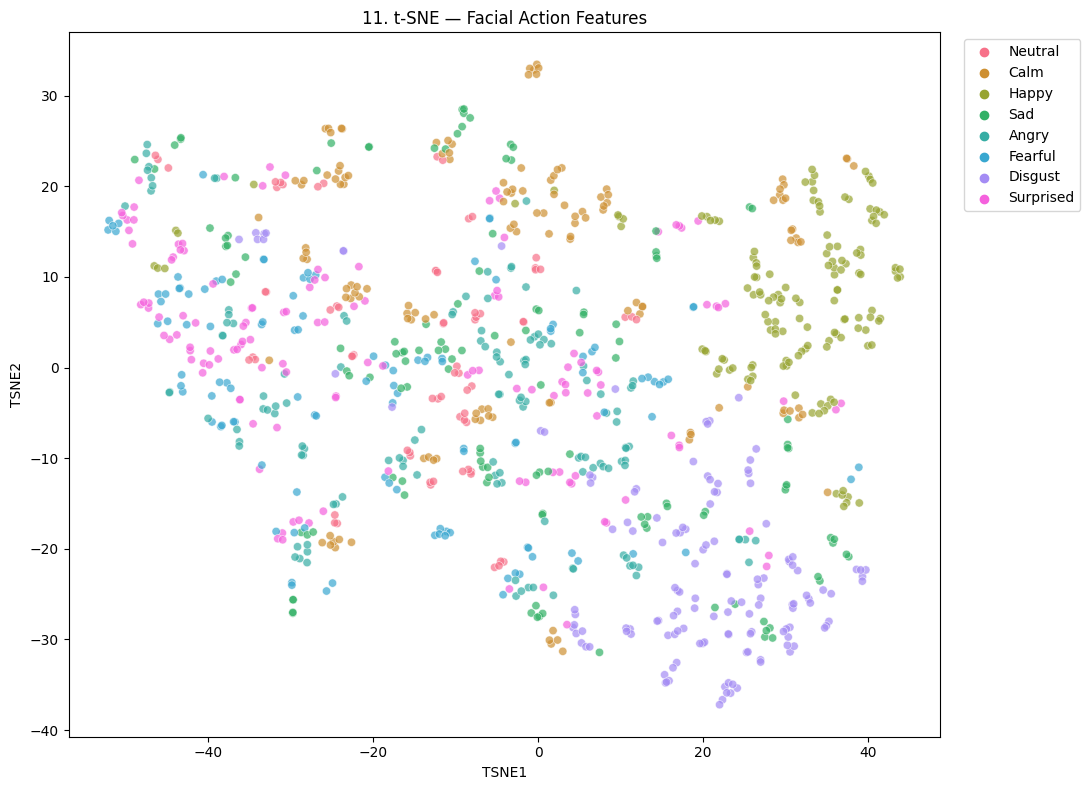

Extracting audio:   0%|          | 0/1440 [00:00<?, ?it/s]

Audio extraction failures: 0
Audio samples: 1440
Audio examples: 8

GRAPH 12: Audio Waveforms
Measures: Audio signal amplitude over time.
Look for: Compare speech dynamics, pauses, and amplitude peaks.


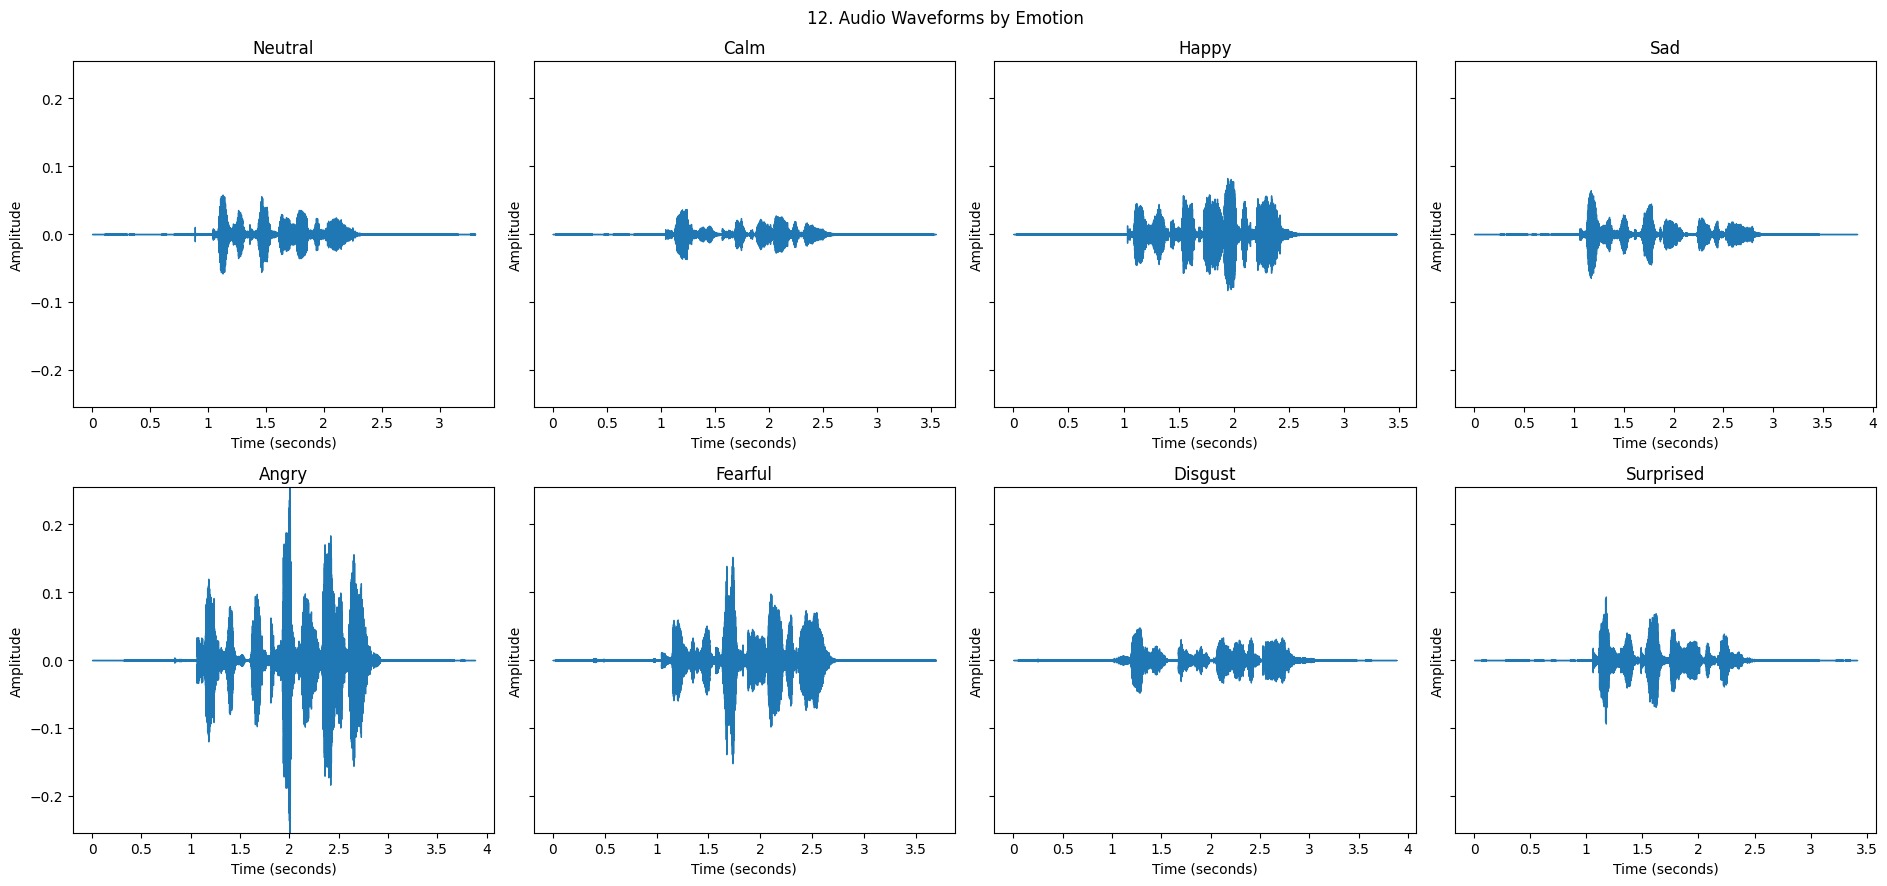


GRAPH 13: Pitch Distribution by Emotion
Measures: Distribution of recording-level median pitch estimates.
Look for: Look for differences, but remember that male and female vocal ranges overlap.


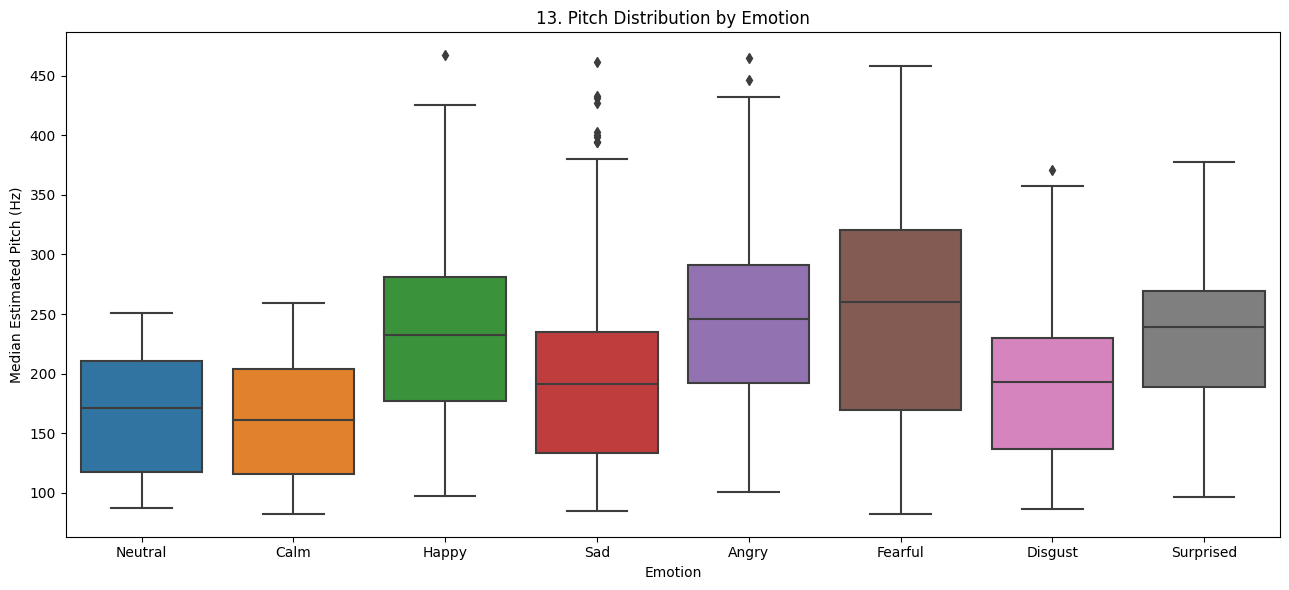


GRAPH 14: Average Pitch by Emotion and Gender
Measures: Mean of recording-level median pitch estimates for male and female actors.
Look for: Compare emotions within each gender to reduce gender-related confounding.


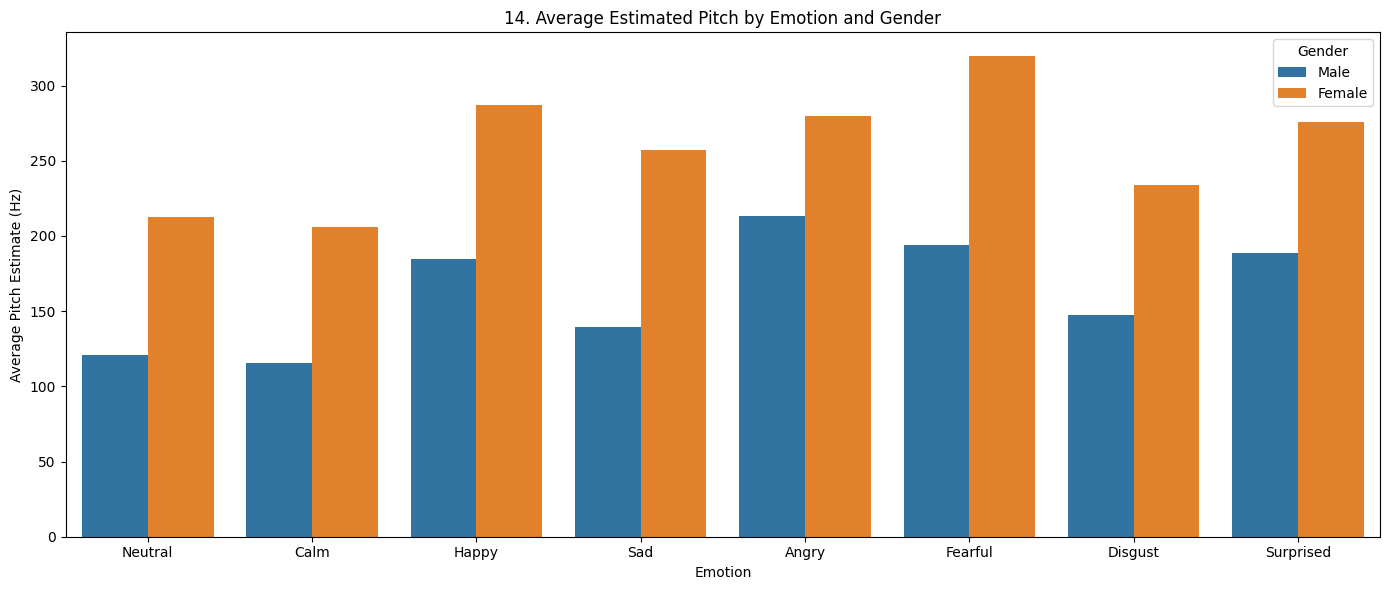


GRAPH 15: Lowest vs Highest Pitch by Gender
Measures: Minimum and maximum recording-level median pitch by emotion and gender.
Look for: Compare pitch ranges within males and females; look for overlap and outliers.


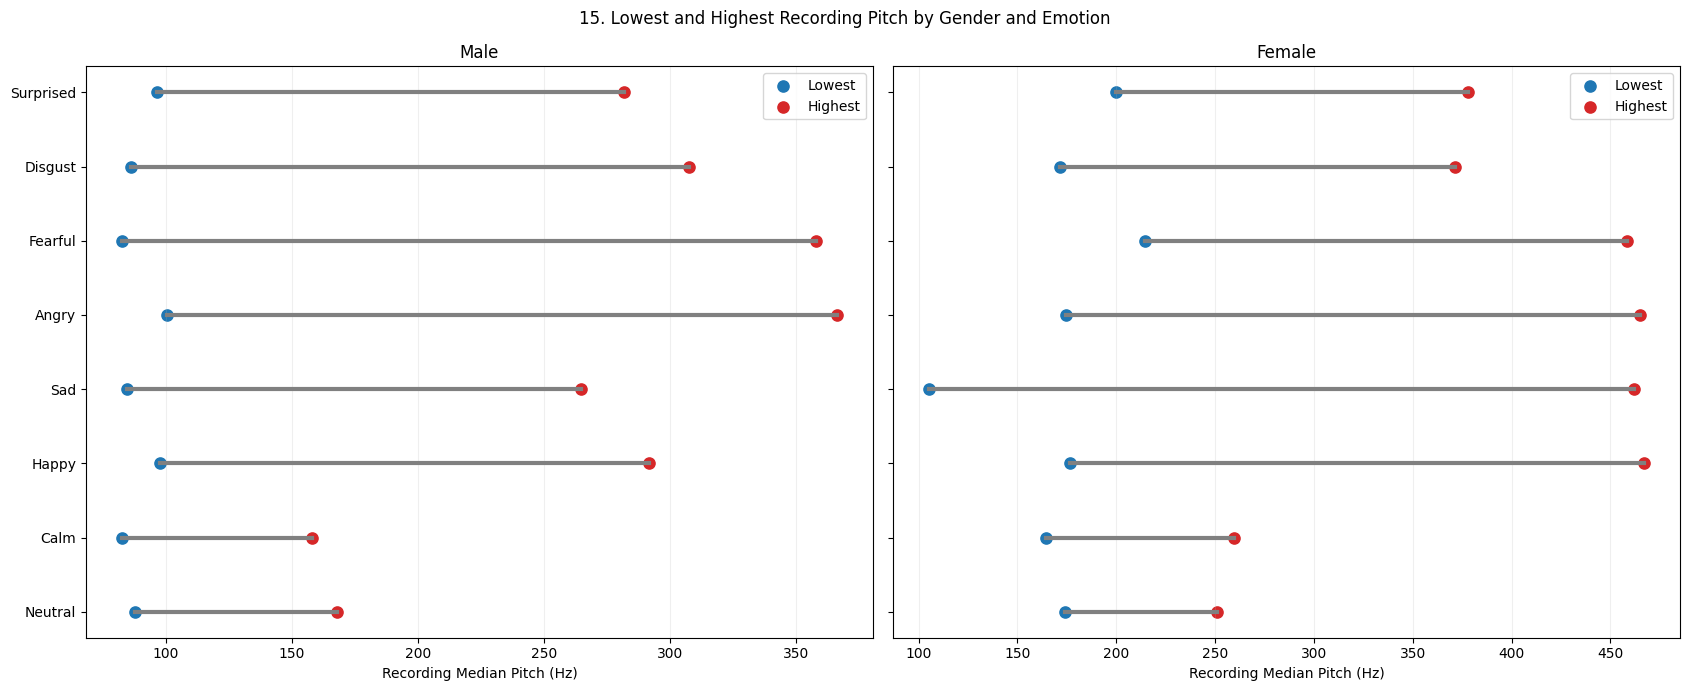


Visualization completed:
11 facial/video graphs
4 audio graphs
Total: 15 graphs
Audio samples analyzed: 1440


In [7]:
# ============================================================
# CELL 7 — SELECTED VIDEO + AUDIO VISUALIZATIONS
# 11 facial/video graphs + 4 audio graphs = 15 graphs
# ============================================================

import subprocess
import shutil
import librosa
import librosa.display
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

df = facial_features_df.copy()
df["Emotion"] = df["emotion"].map(EMOTIONS)

emotion_order = list(EMOTIONS.values())
palette = sns.color_palette("husl", 8)

AU_NAMES = {
    "AU01": "Inner Brow Raiser",
    "AU02": "Outer Brow Raiser",
    "AU04": "Brow Lowerer",
    "AU05": "Upper Lid Raiser",
    "AU06": "Cheek Raiser",
    "AU07": "Lid Tightener",
    "AU09": "Nose Wrinkler",
    "AU10": "Upper Lip Raiser",
    "AU12": "Lip Corner Puller (Smile)",
    "AU14": "Dimpler",
    "AU15": "Lip Corner Depressor",
    "AU17": "Chin Raiser",
    "AU20": "Lip Stretcher",
    "AU23": "Lip Tightener",
    "AU25": "Lips Part",
    "AU26": "Jaw Drop",
    "AU28": "Lip Suck",
    "AU45": "Blink"
}

def au_label(col):
    return AU_NAMES.get(col.split("_")[0], col)

def info(number, name, measures, expected):
    print(f"\nGRAPH {number}: {name}")
    print("Measures:", measures)
    print("Look for:", expected)

def show():
    plt.tight_layout()
    plt.show()

au_r = [c for c in df.columns
        if c.startswith("AU") and c.endswith("_r_mean")]

au_c = [c for c in df.columns
        if c.startswith("AU") and c.endswith("_c_mean")]

gaze_cols = [c for c in df.columns
             if c.startswith("gaze_") and c.endswith("_mean")]

# ============================================================
# PART A — 11 FACIAL / VIDEO GRAPHS
# ============================================================

# 1. FACIAL ACTION INTENSITY HEATMAP
# Brighter cells mean stronger average facial action intensity.

info(1, "Facial Action Intensity Heatmap",
     "Mean intensity of each facial action by emotion.",
     "Happy: smile and cheek raising. Disgust: nose wrinkling and upper-lip raising.")

data = df.groupby("Emotion")[au_r].mean().reindex(emotion_order)
data.columns = [au_label(c) for c in data.columns]

plt.figure(figsize=(17, 7))
sns.heatmap(data, cmap="YlOrRd")
plt.title("1. Average Facial Action Intensity by Emotion")
plt.xlabel("Facial Action")
plt.ylabel("Emotion")
plt.xticks(rotation=45, ha="right")
show()


# 2. FACIAL ACTION ACTIVATION FREQUENCY
# Percentage of frames where each facial action was detected.

info(2, "Facial Action Activation Frequency",
     "Percentage of video frames containing each facial action.",
     "Happy may show frequent smiling; disgust may show frequent nose wrinkling.")

data = df.groupby("Emotion")[au_c].mean().reindex(emotion_order) * 100
data.columns = [au_label(c) for c in data.columns]

plt.figure(figsize=(17, 7))
sns.heatmap(data, cmap="viridis", vmin=0, vmax=100)
plt.title("2. Facial Action Activation Frequency (%)")
plt.xlabel("Facial Action")
plt.ylabel("Emotion")
plt.xticks(rotation=45, ha="right")
show()


# 3. FACIAL ACTION CORRELATION MATRIX
# +1 means actions tend to increase together.
# -1 means actions tend to move in opposite directions.

info(3, "Facial Action Correlation",
     "Relationships between facial action intensities.",
     "Cheek raising and smiling may correlate; brow lowering and eyelid tightening may correlate.")

corr = df[au_r].corr()
corr.index = [au_label(c) for c in corr.index]
corr.columns = [au_label(c) for c in corr.columns]

plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("3. Correlation Between Facial Actions")
plt.xticks(rotation=90)
show()


# 4. NORMAL VS STRONG FACIAL EXPRESSIONS
# Compares normal and strong intensity recordings.

info(4, "Normal vs Strong Facial Expressions",
     "Facial action intensity for normal and strong expressions.",
     "Strong expressions may show higher intensity in some facial actions.")

selected_aus = au_r[:8]

temp = df.melt(
    id_vars=["Emotion", "intensity"],
    value_vars=selected_aus,
    var_name="Action",
    value_name="Intensity"
)
temp["Action"] = temp["Action"].map(au_label)
temp["Intensity Level"] = temp["intensity"].map(INTENSITY)

plt.figure(figsize=(17, 7))
sns.boxplot(data=temp, x="Action", y="Intensity",
            hue="Intensity Level")
plt.title("4. Facial Actions: Normal vs Strong")
plt.xticks(rotation=35, ha="right")
show()


# 5. FACIAL ACTION RADAR PROFILES
# Each line represents one emotion's average facial action profile.

info(5, "Facial Action Radar Profiles",
     "Average facial action profile of each emotion.",
     "Look for distinct shapes; smiling actions may distinguish Happy.")

radar_aus = au_r[:8]
means = df.groupby("Emotion")[radar_aus].mean().reindex(emotion_order)

labels = [au_label(c) for c in radar_aus]
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"polar": True})

for emotion in emotion_order:
    values = means.loc[emotion].tolist()
    values += values[:1]
    ax.plot(angles, values, label=emotion)
    ax.fill(angles, values, alpha=0.04)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)
ax.set_title("5. Facial Action Profiles by Emotion", pad=25)
ax.legend(bbox_to_anchor=(1.3, 1.1))
show()


# 6. FACIAL ACTION EVOLUTION OVER TIME
# One recording per emotion.
# X = time; Y = facial action intensity.

info(6, "Facial Action Evolution Over Time",
     "Changes in facial action intensity throughout one video per emotion.",
     "Look for expression onset, intensity peaks, and relaxation.")

fig, axes = plt.subplots(2, 4, figsize=(19, 9))

for emotion, ax in zip(EMOTIONS.keys(), axes.flat):
    match = av_df[av_df.emotion == emotion]

    if len(match):
        raw_emotion = pd.read_csv(match.iloc[0]["csv_path"])
        cols = [c for c in raw_emotion.columns
                if c.startswith("AU") and c.endswith("_r")][:4]

        for col in cols:
            ax.plot(
                raw_emotion["timestamp"],
                raw_emotion[col],
                label=au_label(col),
                alpha=0.8
            )

        ax.set_title(EMOTIONS[emotion])
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Facial Action Intensity")

plt.suptitle("6. Facial Action Evolution Over Time")
show()


# Read one example CSV for the remaining temporal graphs
raw = pd.read_csv(av_df.iloc[0]["csv_path"])


# 7. GAZE X, Y, Z BY EMOTION
# X = horizontal gaze-vector component
# Y = vertical gaze-vector component
# Z = forward/depth gaze-vector component
# The signs depend on OpenFace's camera coordinate convention.

info(7, "Gaze Direction Components",
     "Average X, Y and Z gaze-vector components for both eyes.",
     "Look for differences in gaze direction and variation across emotions.")

gaze_selected = [
    c for c in gaze_cols
    if any(s in c for s in ["_x_", "_y_", "_z_"])
]

temp = df.melt(
    id_vars="Emotion",
    value_vars=gaze_selected,
    var_name="Gaze Component",
    value_name="Value"
)

plt.figure(figsize=(18, 7))
sns.boxplot(data=temp, x="Gaze Component", y="Value", hue="Emotion")
plt.title("7. Gaze X, Y and Z Components by Emotion")
plt.xticks(rotation=45, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1))
show()


# 8. GAZE DIRECTION OVER TIME
# Compares left and right eye direction components.
# Changes in X/Y/Z indicate changes in gaze direction.

info(8, "Gaze Direction Over Time",
     "Left and right eye gaze direction throughout a recording.",
     "Look for gaze shifts, stability, and differences between the eyes.")

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for ax, axis_name in zip(axes, ["x", "y", "z"]):
    for eye in [0, 1]:
        col = f"gaze_{eye}_{axis_name}"
        if col in raw.columns:
            ax.plot(raw["timestamp"], raw[col], label=f"Eye {eye}")

    ax.set_ylabel(f"Gaze {axis_name.upper()}")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (seconds)")
plt.suptitle("8. Gaze X, Y and Z Over Time")
show()


# 9. HAPPY VS ANGRY — AVERAGE FACIAL LANDMARKS

info(9, "Happy vs Angry Average Facial Landmarks",
     "Average positions of 68 facial landmarks across all recordings.",
     "Compare the average positions of the eyes, eyebrows, nose, and mouth.")

def get_average_landmarks(emotion_code):
    emotion_files = av_df[av_df.emotion == emotion_code]
    all_landmarks = []

    for row in tqdm(
        emotion_files.itertuples(index=False),
        total=len(emotion_files),
        desc=f"Processing {EMOTIONS[emotion_code]}"
    ):
        face = pd.read_csv(row.csv_path)

        x_cols = [f"x_{i}" for i in range(68)]
        y_cols = [f"y_{i}" for i in range(68)]

        if all(c in face.columns for c in x_cols + y_cols):
            x = face[x_cols].mean()
            y = face[y_cols].mean()
            all_landmarks.append(
                np.column_stack([x.to_numpy(), y.to_numpy()])
            )

    return np.mean(all_landmarks, axis=0)

happy_avg = get_average_landmarks(3)
angry_avg = get_average_landmarks(5)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, landmarks, emotion, color in zip(
    axes,
    [happy_avg, angry_avg],
    ["Happy", "Angry"],
    ["seagreen", "crimson"]
):
    ax.scatter(
        landmarks[:, 0],
        landmarks[:, 1],
        color=color,
        s=25,
        alpha=0.8
    )

    ax.set_title(f"Average {emotion} Face")
    ax.set_xlabel("X Position")
    ax.set_ylabel("Y Position")
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.grid(alpha=0.2)

plt.suptitle("9. Average Facial Landmarks: Happy vs Angry")
plt.tight_layout()
plt.show()

# 10. TRACKING CONFIDENCE
# Higher confidence generally means more reliable face tracking.

info(10, "Facial Tracking Confidence",
     "Average OpenFace tracking confidence per recording.",
     "Confidence should ideally remain high across all emotions.")

plt.figure(figsize=(12, 5))
sns.violinplot(data=df, x="Emotion", y="confidence",
               order=emotion_order)
plt.title("10. Facial Tracking Confidence by Emotion")
show()


# 11. t-SNE OF FACIAL ACTIONS
# Projects high-dimensional facial action features into 2D.
# Nearby points may have similar facial action profiles.

info(11, "t-SNE of Facial Actions",
     "Nonlinear 2D representation of facial action features.",
     "Look for emotion groupings and overlap, without treating clusters as proof of accuracy.")

X = df[au_r].replace([np.inf, -np.inf], np.nan).fillna(0)
X_scaled = StandardScaler().fit_transform(X)

n = min(1000, len(X_scaled))
rng = np.random.RandomState(42)
indices = rng.choice(len(X_scaled), n, replace=False)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

coords = tsne.fit_transform(X_scaled[indices])

tsne_df = pd.DataFrame(coords, columns=["TSNE1", "TSNE2"])
tsne_df["Emotion"] = df.iloc[indices]["Emotion"].values

plt.figure(figsize=(11, 8))
sns.scatterplot(
    data=tsne_df, x="TSNE1", y="TSNE2",
    hue="Emotion", hue_order=emotion_order,
    alpha=0.7, palette=palette
)
plt.title("11. t-SNE — Facial Action Features")
plt.legend(bbox_to_anchor=(1.02, 1))
show()


# ============================================================
# PART B — AUDIO EXTRACTION USING FFMPEG
# ============================================================

# FFmpeg decodes MP4 audio directly, avoiding the PySoundFile /
# audioread fallback and deprecation warnings.
# Audio pitch summaries are cached to avoid repeating extraction.

if shutil.which("ffmpeg") is None:
    raise RuntimeError("FFmpeg is required to decode the MP4 audio.")

def load_video_audio(path):
    command = [
        "ffmpeg", "-nostdin", "-v", "error",
        "-i", str(path), "-vn",
        "-f", "f32le", "-acodec", "pcm_f32le",
        "-ac", "1", "-ar", str(SAMPLE_RATE),
        "pipe:1"
    ]
    result = subprocess.run(
        command, stdout=subprocess.PIPE,
        stderr=subprocess.PIPE, check=True
    )
    return np.frombuffer(result.stdout, dtype=np.float32).copy()


# Approximate pitch using YIN, excluding very low-energy frames.
# Silence filtering reduces, but does not eliminate, unvoiced errors.

HOP = 256
FRAME = 1024

def pitch_track(y):
    f0 = librosa.yin(
        y, fmin=65, fmax=500, sr=SAMPLE_RATE,
        frame_length=FRAME, hop_length=HOP
    )
    rms = librosa.feature.rms(
        y=y, frame_length=FRAME, hop_length=HOP
    )[0]

    n = min(len(f0), len(rms))
    f0, rms = f0[:n], rms[:n]

    voiced = rms > max(1e-5, 0.15 * rms.max())
    f0 = np.where(voiced, f0, np.nan)
    return f0

cache_path = OUTPUT_DIR / "audio_pitch_summary_v2.csv"

if cache_path.exists():
    audio_df = pd.read_csv(cache_path)
    print("Loaded cached audio pitch features.")
else:
    audio_rows = []
    errors = []

    for row in tqdm(av_df.itertuples(index=False),
                    total=len(av_df), desc="Extracting audio"):
        try:
            y = load_video_audio(row.video_path)
            if len(y) == 0:
                raise ValueError("Empty audio track")

            f0 = pitch_track(y)
            valid = f0[np.isfinite(f0)]

            audio_rows.append({
                "filename": row.filename,
                "emotion": row.emotion,
                "actor": row.actor,
                "pitch": np.median(valid) if len(valid) else np.nan
            })

        except Exception as e:
            errors.append((row.filename, str(e)))

    audio_df = pd.DataFrame(audio_rows)
    audio_df.to_csv(cache_path, index=False)

    print("Audio extraction failures:", len(errors))
    if errors:
        print("First errors:", errors[:3])

audio_df["Emotion"] = audio_df["emotion"].map(EMOTIONS)
audio_df["Gender"] = np.where(
    audio_df["actor"] % 2 == 1, "Male", "Female"
)

# Keep only one waveform per emotion for the example plots.
audio_examples = {}

for emotion in EMOTIONS:
    matching = av_df[av_df.emotion == emotion]

    for row in matching.itertuples(index=False):
        try:
            y = load_video_audio(row.video_path)
            if len(y):
                audio_examples[emotion] = y
                break
        except Exception:
            continue

print("Audio samples:", len(audio_df))
print("Audio examples:", len(audio_examples))


# ============================================================
# PART C — 4 AUDIO GRAPHS
# ============================================================

# 12. AUDIO WAVEFORMS
# X = time, Y = amplitude.
# Larger peaks represent stronger signal amplitude.
# Angry speech may have stronger peaks, but recording gain matters.
# All emotion plots use the same amplitude scale for fair comparison.

info(12, "Audio Waveforms",
     "Audio signal amplitude over time.",
     "Compare speech dynamics, pauses, and amplitude peaks.")

max_amplitude = max(
    (np.max(np.abs(y)) for y in audio_examples.values() if len(y)),
    default=1.0
)

fig, axes = plt.subplots(2, 4, figsize=(19, 9), sharey=True)

for emotion, ax in zip(EMOTIONS.keys(), axes.flat):
    if emotion in audio_examples:
        librosa.display.waveshow(
            audio_examples[emotion], sr=SAMPLE_RATE, ax=ax
        )
        ax.set_ylim(-max_amplitude, max_amplitude)
        ax.set_title(EMOTIONS[emotion])
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")

plt.suptitle("12. Audio Waveforms by Emotion")
show()


# 13. PITCH DISTRIBUTION BY EMOTION
# Each point in the distribution represents one recording's median
# estimated pitch. Gender and actor identity can affect pitch.

info(13, "Pitch Distribution by Emotion",
     "Distribution of recording-level median pitch estimates.",
     "Look for differences, but remember that male and female vocal ranges overlap.")

plt.figure(figsize=(13, 6))
sns.boxplot(
    data=audio_df, x="Emotion", y="pitch",
    order=emotion_order
)
plt.title("13. Pitch Distribution by Emotion")
plt.ylabel("Median Estimated Pitch (Hz)")
show()


# 14. AVERAGE PITCH PER EMOTION AND GENDER
# This averages recording-level median pitch estimates within
# each emotion and gender group.
# Expected: female actors may have higher average pitch,
# but compare emotional changes within each gender separately.

info(14, "Average Pitch by Emotion and Gender",
     "Mean of recording-level median pitch estimates for male and female actors.",
     "Compare emotions within each gender to reduce gender-related confounding.")

plt.figure(figsize=(14, 6))
sns.barplot(
    data=audio_df, x="Emotion", y="pitch",
    hue="Gender", order=emotion_order,
    hue_order=["Male", "Female"],
    errorbar=None
)
plt.title("14. Average Estimated Pitch by Emotion and Gender")
plt.xlabel("Emotion")
plt.ylabel("Average Pitch Estimate (Hz)")
plt.legend(title="Gender")
show()


# 15. LOWEST VS HIGHEST PITCH BY GENDER
# Each line spans the lowest to highest recording-level
# median pitch estimate for one emotion and gender.
# These are extremes of recording medians, not instantaneous F0 peaks.
# Outliers and pitch estimation errors can affect the endpoints.

info(15, "Lowest vs Highest Pitch by Gender",
     "Minimum and maximum recording-level median pitch by emotion and gender.",
     "Compare pitch ranges within males and females; look for overlap and outliers.")

pitch_range = (
    audio_df.groupby(["Gender", "Emotion"])["pitch"]
    .agg(["min", "max"])
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)

for ax, gender in zip(axes, ["Male", "Female"]):
    subset = pitch_range[pitch_range["Gender"] == gender]
    subset = subset.set_index("Emotion").reindex(emotion_order)

    y_pos = np.arange(len(emotion_order))

    for i, emotion in enumerate(emotion_order):
        low = subset.loc[emotion, "min"]
        high = subset.loc[emotion, "max"]

        if pd.notna(low) and pd.notna(high):
            ax.plot([low, high], [i, i],
                    linewidth=3, color="gray")
            ax.scatter(low, i, color="tab:blue",
                       s=65, label="Lowest" if i == 0 else "")
            ax.scatter(high, i, color="tab:red",
                       s=65, label="Highest" if i == 0 else "")

    ax.set_yticks(y_pos)
    ax.set_yticklabels(emotion_order)
    ax.invert_yaxis()
    ax.set_xlabel("Recording Median Pitch (Hz)")
    ax.set_title(gender)
    ax.grid(axis="x", alpha=0.2)
    ax.legend()

plt.suptitle("15. Lowest and Highest Recording Pitch by Gender and Emotion")
show()


# ============================================================
# SUMMARY
# ============================================================

print("\nVisualization completed:")
print("11 facial/video graphs")
print("4 audio graphs")
print("Total: 15 graphs")
print("Audio samples analyzed:", len(audio_df))

Loaded cached facial comparison features.


## Male Voice — Lowest vs Highest Pitch

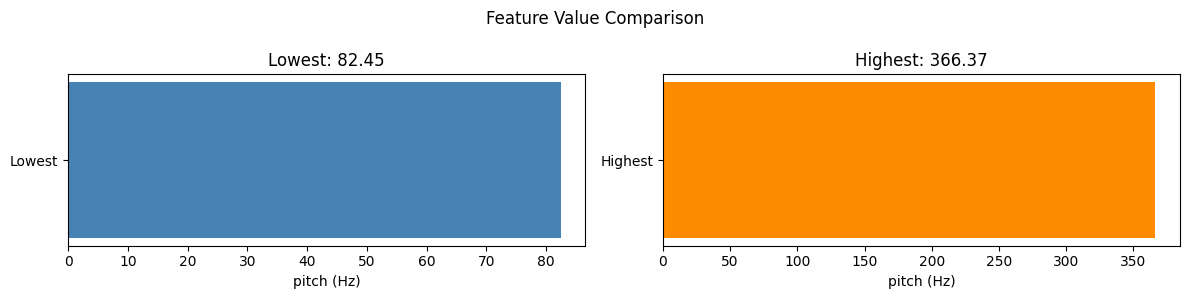

LOWEST: 01-01-02-02-01-02-09
HIGHEST: 01-01-05-02-02-02-13


---

## Female Voice — Lowest vs Highest Pitch

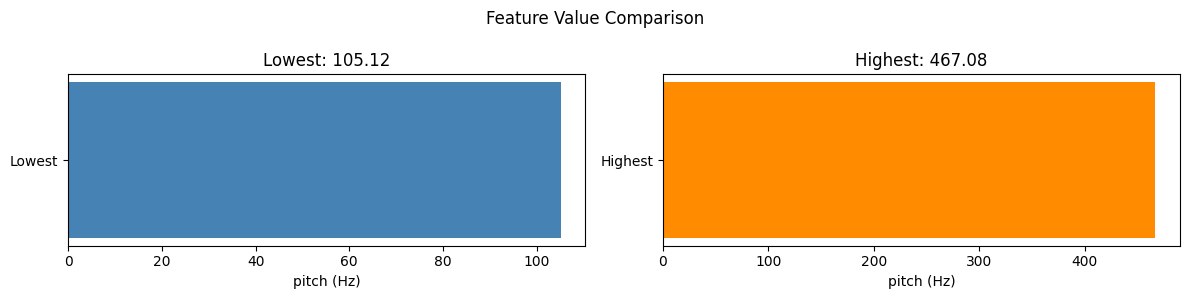

LOWEST: 01-01-04-01-02-02-20
HIGHEST: 01-01-03-02-02-01-10


---

## Happy — Strongest vs Weakest Smile

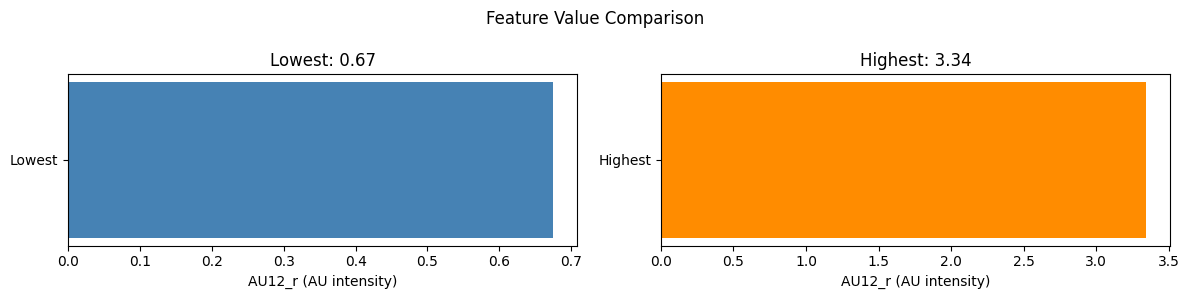

LOWEST: 01-01-03-01-01-01-11
HIGHEST: 01-01-03-01-01-02-18


---

## Angry — Strongest vs Weakest Brow Lowering

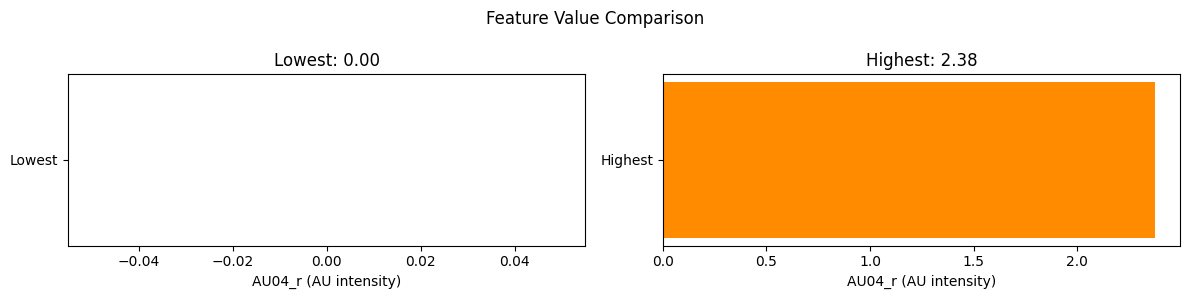

LOWEST: 01-01-05-01-01-01-10
HIGHEST: 01-01-05-02-02-02-09


---

## Disgust — Strongest vs Weakest Brow Lowering

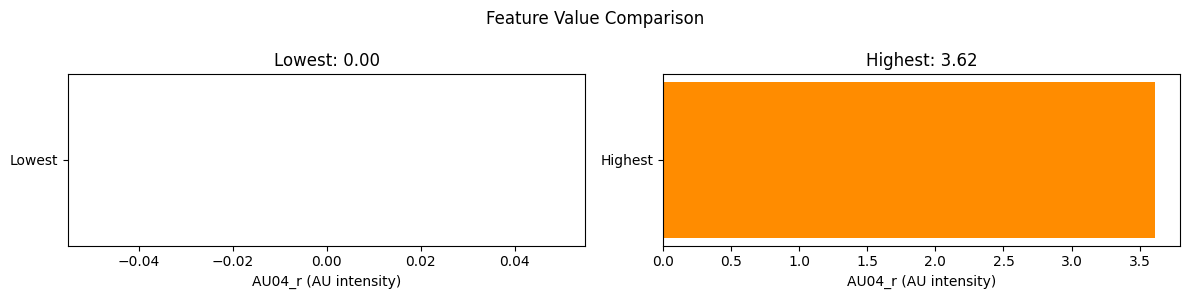

LOWEST: 01-01-07-01-02-01-13
HIGHEST: 01-01-07-02-01-01-17


---

## Disgust — Strongest vs Weakest Nose Wrinkling

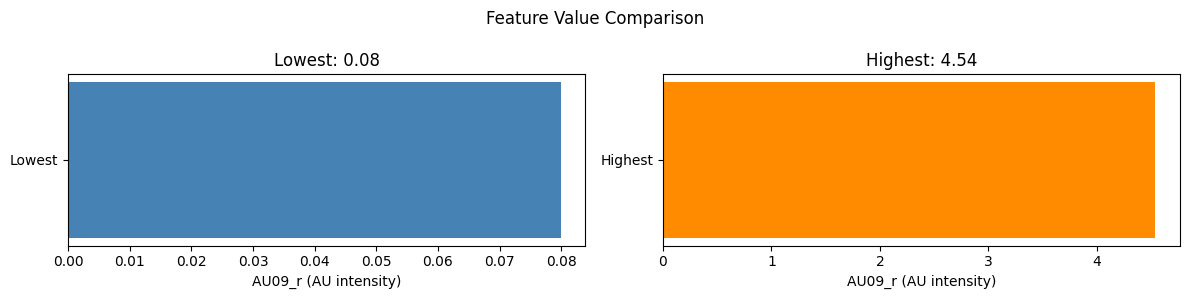

LOWEST: 01-01-07-01-01-02-05
HIGHEST: 01-01-07-02-02-02-03


---

## Surprised — Strongest vs Weakest Jaw Drop

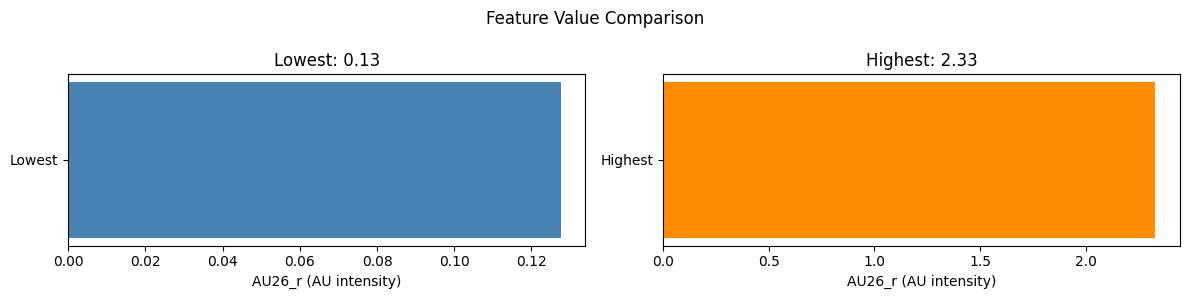

LOWEST: 01-01-08-01-02-01-20
HIGHEST: 01-01-08-02-01-01-12


---

## Neutral / Calm — Highest vs Lowest Jaw Drop

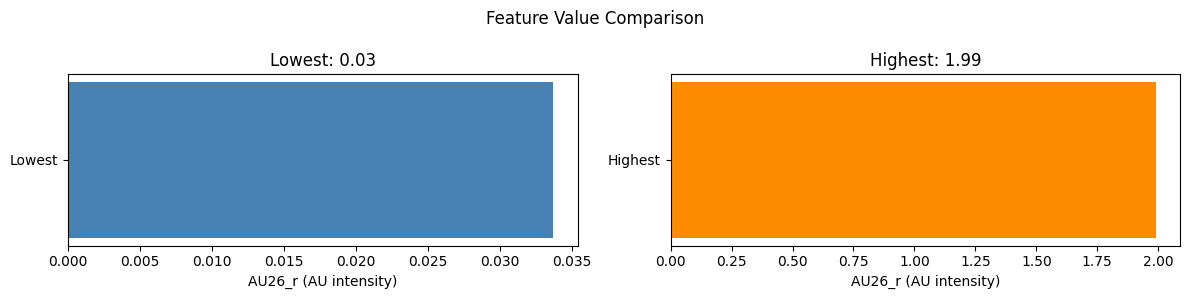

LOWEST: 01-01-02-02-02-02-16
HIGHEST: 01-01-01-01-02-01-12


---

## Fearful — Strongest vs Weakest Eyelid Raising

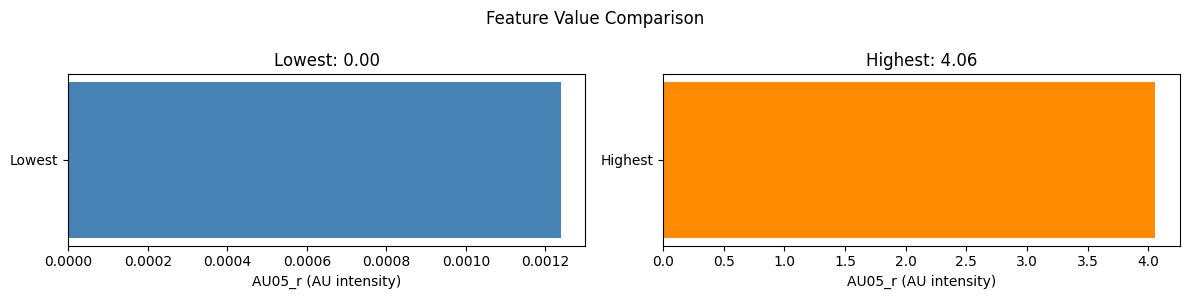

LOWEST: 01-01-06-01-01-02-07
HIGHEST: 01-01-06-02-01-02-24


---

All comparative examples completed.


In [13]:

# ============================================================
# CELL 8 — COMPARATIVE VIDEO EXAMPLES
# Highest vs Lowest facial and audio feature values
# Cached facial extraction + lightweight playable video display
# ============================================================

from IPython.display import display, Video, HTML, Markdown

# ------------------------------------------------------------
# 1. EXTRACT OR LOAD FACIAL COMPARISON FEATURES
# ------------------------------------------------------------

comparison_features = {
    "AU12_r": "Smile intensity",
    "AU04_r": "Brow lowering",
    "AU09_r": "Nose wrinkling",
    "AU05_r": "Upper eyelid raising",
    "AU26_r": "Jaw dropping"
}

metrics_cache = OUTPUT_DIR / "video_comparison_features_v1.csv"

video_metrics_df = None

if metrics_cache.exists():
    cached = pd.read_csv(metrics_cache)

    cache_is_valid = (
        len(cached) == len(av_df)
        and cached["filename"].is_unique
        and set(cached["filename"]) == set(av_df["filename"])
    )

    if cache_is_valid:
        video_metrics_df = cached
        print("Loaded cached facial comparison features.")
    else:
        print("Cache incomplete. Recalculating facial features.")


# Extract only if no valid cache exists.
if video_metrics_df is None:

    video_metrics = []

    for row in tqdm(
        av_df.itertuples(index=False),
        total=len(av_df),
        desc="Extracting facial comparison features"
    ):
        face = pd.read_csv(row.csv_path)

        result = {
            "filename": row.filename,
            "emotion": row.emotion,
            "actor": row.actor
        }

        for feature in comparison_features:
            result[feature] = (
                face[feature].mean()
                if feature in face.columns
                else np.nan
            )

        video_metrics.append(result)

    video_metrics_df = pd.DataFrame(video_metrics)

    video_metrics_df.to_csv(metrics_cache, index=False)

    print("Facial comparison features cached.")


# Add video paths from the original paired dataset.
video_path_lookup = av_df.set_index("filename")["video_path"]

video_metrics_df["video_path"] = (
    video_metrics_df["filename"].map(video_path_lookup)
)


# ------------------------------------------------------------
# 2. COMPARISON DEFINITIONS
# ------------------------------------------------------------

comparisons = [
    {
        "title": "Male Voice — Lowest vs Highest Pitch",
        "type": "audio",
        "feature": "pitch",
        "gender": "Male"
    },
    {
        "title": "Female Voice — Lowest vs Highest Pitch",
        "type": "audio",
        "feature": "pitch",
        "gender": "Female"
    },
    {
        "title": "Happy — Strongest vs Weakest Smile",
        "type": "face",
        "emotion": [3],
        "feature": "AU12_r"
    },
    {
        "title": "Angry — Strongest vs Weakest Brow Lowering",
        "type": "face",
        "emotion": [5],
        "feature": "AU04_r"
    },
    {
        "title": "Disgust — Strongest vs Weakest Brow Lowering",
        "type": "face",
        "emotion": [7],
        "feature": "AU04_r"
    },
    {
        "title": "Disgust — Strongest vs Weakest Nose Wrinkling",
        "type": "face",
        "emotion": [7],
        "feature": "AU09_r"
    },
    {
        "title": "Surprised — Strongest vs Weakest Jaw Drop",
        "type": "face",
        "emotion": [8],
        "feature": "AU26_r"
    },
    {
        "title": "Neutral / Calm — Highest vs Lowest Jaw Drop",
        "type": "face",
        "emotion": [1, 2],
        "feature": "AU26_r"
    },
    {
        "title": "Fearful — Strongest vs Weakest Eyelid Raising",
        "type": "face",
        "emotion": [6],
        "feature": "AU05_r"
    }
]


# ------------------------------------------------------------
# 3. HELPER: DISPLAY TWO VIDEOS SIDE BY SIDE
# ------------------------------------------------------------


# ------------------------------------------------------------
# HELPER: DISPLAY TWO VIDEOS SIDE BY SIDE
# ------------------------------------------------------------


# ------------------------------------------------------------
# HELPER: CREATE LIGHTWEIGHT VIDEO PREVIEWS
# AND DISPLAY TWO PLAYABLE VIDEOS SIDE BY SIDE
# ------------------------------------------------------------

import subprocess

PREVIEW_DIR = OUTPUT_DIR / "video_previews"
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)


def create_video_preview(video_path):

    if video_path is None or pd.isna(video_path):
        raise ValueError("Missing video path.")

    source = Path(video_path)

    if not source.is_file():
        raise FileNotFoundError(f"Video not found: {source}")

    preview_path = PREVIEW_DIR / f"{source.stem}_preview.mp4"

    # Reuse an existing preview to avoid encoding it again.
    if preview_path.exists() and preview_path.stat().st_size > 0:
        return preview_path

    command = [
        "ffmpeg",
        "-nostdin",
        "-y",
        "-v", "error",
        "-i", str(source),

        # Reduce resolution and frame rate.
        "-vf", "scale='min(480,iw)':-2,fps=20",

        # Compress video while maintaining reasonable quality.
        "-c:v", "libx264",
        "-preset", "veryfast",
        "-crf", "30",
        "-pix_fmt", "yuv420p",

        # Keep audio for voice comparisons.
        "-c:a", "aac",
        "-b:a", "64k",
        "-ac", "1",

        "-movflags", "+faststart",
        str(preview_path)
    ]

    try:
        subprocess.run(
            command,
            check=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE
        )
    except subprocess.CalledProcessError as e:
        raise RuntimeError(
            f"Could not create preview for {source.name}:\n"
            f"{e.stderr.decode(errors='replace')}"
        )

    return preview_path


def display_video_pair(lowest, highest):

    lowest_preview = create_video_preview(
        lowest["video_path"]
    )

    highest_preview = create_video_preview(
        highest["video_path"]
    )

    # Embed the compressed previews directly into the notebook.
    # Unlike embed=False, playback does not depend on Kaggle
    # serving the original /kaggle/input files.

    lowest_video = Video(
        str(lowest_preview),
        embed=True,
        width=430,
        html_attributes='controls preload="none"'
    )

    highest_video = Video(
        str(highest_preview),
        embed=True,
        width=430,
        html_attributes='controls preload="none"'
    )

    lowest_html = lowest_video._repr_html_()
    highest_html = highest_video._repr_html_()

    display(HTML(f"""
    <div style="
        display: flex;
        flex-wrap: wrap;
        gap: 20px;
        align-items: flex-start;
    ">
        <div style="flex: 1; min-width: 320px;">
            <h4>Lowest example</h4>
            {lowest_html}
        </div>

        <div style="flex: 1; min-width: 320px;">
            <h4>Highest example</h4>
            {highest_html}
        </div>
    </div>
    """))

# ------------------------------------------------------------
# 4. RUN ALL COMPARISONS
# ------------------------------------------------------------

for comparison in comparisons:

    feature = comparison["feature"]

    # Select candidates.
    if comparison["type"] == "audio":

        candidates = audio_df[
            audio_df["Gender"] == comparison["gender"]
        ].copy()

        candidates = candidates.dropna(subset=[feature])

        candidates["video_path"] = (
            candidates["filename"].map(video_path_lookup)
        )

    else:

        candidates = video_metrics_df[
            video_metrics_df["emotion"].isin(comparison["emotion"])
        ].copy()

        candidates = candidates.dropna(subset=[feature])


    # Keep only recordings whose video file exists.
    candidates = candidates[
        candidates["video_path"].apply(
            lambda p: isinstance(p, str) and Path(p).is_file()
        )
    ]

    if len(candidates) < 2:
        print("Not enough valid recordings:", comparison["title"])
        continue


    # Find lowest and highest values.
    lowest = candidates.loc[candidates[feature].idxmin()]
    highest = candidates.loc[candidates[feature].idxmax()]

    if lowest["filename"] == highest["filename"]:
        print("No distinct lowest/highest examples:", comparison["title"])
        continue


    display(Markdown(f"## {comparison['title']}"))

    unit = "Hz" if comparison["type"] == "audio" else "AU intensity"

    # Feature comparison chart.
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))

    for ax, selected, label, color in zip(
        axes,
        [lowest, highest],
        ["Lowest", "Highest"],
        ["steelblue", "darkorange"]
    ):
        ax.barh(label, selected[feature], color=color)
        ax.set_xlabel(f"{feature} ({unit})")
        ax.set_title(f"{label}: {selected[feature]:.2f}")

    plt.suptitle("Feature Value Comparison")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    print("LOWEST:", lowest["filename"])
    print("HIGHEST:", highest["filename"])

    # Playable videos, side by side.
    display_video_pair(lowest, highest)

    display(Markdown("---"))


print("All comparative examples completed.")


In [15]:

# ============================================================
# CELL 9 — MULTIMODAL DATASET PREPARATION
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# ------------------------------------------------------------
# 1. EXTRACT AUDIO FEATURES (OR LOAD CACHE)
# ------------------------------------------------------------

audio_cache = OUTPUT_DIR / "audio_features_v1.csv"

def add_stats(result, name, values):
    values = np.asarray(values).ravel()
    values = values[np.isfinite(values)]
    result[f"{name}_mean"] = values.mean() if len(values) else np.nan
    result[f"{name}_std"] = values.std() if len(values) else np.nan


if audio_cache.exists():
    cached = pd.read_csv(audio_cache)
    valid = (
        len(cached) == len(av_df)
        and cached["filename"].is_unique
        and set(cached["filename"]) == set(av_df["filename"])
    )
else:
    valid = False

if valid:
    audio_features_df = cached
    print("Loaded cached audio features.")

else:
    rows, errors = [], []

    for row in tqdm(av_df.itertuples(index=False),
                    total=len(av_df), desc="Audio features"):

        try:
            y = load_video_audio(row.video_path)
            result = {"filename": row.filename}

            mfcc = librosa.feature.mfcc(
                y=y, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
                n_fft=2048, hop_length=HOP
            )

            delta = librosa.feature.delta(mfcc)

            for prefix, matrix in [
                ("mfcc", mfcc),
                ("mfcc_delta", delta)
            ]:
                for i, values in enumerate(matrix, 1):
                    add_stats(result, f"{prefix}_{i:02d}", values)

            acoustic = {
                "rms": librosa.feature.rms(
                    y=y, frame_length=2048, hop_length=HOP
                )[0],
                "zcr": librosa.feature.zero_crossing_rate(
                    y, frame_length=2048, hop_length=HOP
                )[0],
                "spectral_centroid": librosa.feature.spectral_centroid(
                    y=y, sr=SAMPLE_RATE, n_fft=2048, hop_length=HOP
                )[0],
                "spectral_bandwidth": librosa.feature.spectral_bandwidth(
                    y=y, sr=SAMPLE_RATE, n_fft=2048, hop_length=HOP
                )[0],
                "spectral_rolloff": librosa.feature.spectral_rolloff(
                    y=y, sr=SAMPLE_RATE, n_fft=2048, hop_length=HOP
                )[0]
            }

            for name, values in acoustic.items():
                add_stats(result, name, values)

            rows.append(result)

        except Exception as e:
            errors.append((row.filename, str(e)))

    if errors:
        raise RuntimeError(f"Audio extraction failed: {errors[:3]}")

    audio_features_df = pd.DataFrame(rows)
    audio_features_df.to_csv(audio_cache, index=False)


# Add median pitch from Cell 7.
audio_model_df = audio_features_df.merge(
    audio_df[["filename", "pitch"]].rename(
        columns={"pitch": "pitch_median_hz"}
    ),
    on="filename",
    validate="one_to_one"
)

audio_cols = [c for c in audio_model_df.columns if c != "filename"]


# ------------------------------------------------------------
# 2. SELECT FACIAL FEATURES
# ------------------------------------------------------------

facial_cols = [
    c for c in facial_features_df.columns
    if (
        (c.startswith("AU") and c.endswith(
            ("_r_mean", "_r_std", "_c_mean", "_c_std")
        ))
        or
        (c.startswith(("pose_", "gaze_")) and
         c.endswith(("_mean", "_std")))
    )
]

facial_model_df = facial_features_df[
    ["filename"] + facial_cols
].copy()


# ------------------------------------------------------------
# 3. COMBINE BOTH MODALITIES
# ------------------------------------------------------------

metadata_cols = [
    "filename", "emotion", "intensity",
    "statement", "repetition", "actor"
]

multimodal_df = (
    av_df[metadata_cols]
    .merge(facial_model_df, on="filename", validate="one_to_one")
    .merge(audio_model_df, on="filename", validate="one_to_one")
)

FEATURE_COLUMNS = facial_cols + audio_cols
TARGET_COL = "emotion"

assert len(multimodal_df) == len(av_df)
assert multimodal_df["filename"].is_unique

X = multimodal_df[FEATURE_COLUMNS].to_numpy(dtype=np.float64)

print("Recordings:", len(multimodal_df))
print("Facial features:", len(facial_cols))
print("Audio features:", len(audio_cols))
print("Total features:", len(FEATURE_COLUMNS))
print("Missing values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())


# ------------------------------------------------------------
# 4. ACTOR-INDEPENDENT SPLIT
# ------------------------------------------------------------

# 20% test actors, then 20% validation actors
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=SEED
)

train_val_idx, test_idx = next(
    splitter.split(multimodal_df, groups=multimodal_df["actor"])
)

train_val = multimodal_df.iloc[train_val_idx].reset_index(drop=True)
test_df = multimodal_df.iloc[test_idx].reset_index(drop=True)

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=SEED
)

train_idx, val_idx = next(
    splitter.split(train_val, groups=train_val["actor"])
)

train_df = train_val.iloc[train_idx].reset_index(drop=True)
val_df = train_val.iloc[val_idx].reset_index(drop=True)


# Verify no actor appears in multiple splits.
train_actors = set(train_df.actor)
val_actors = set(val_df.actor)
test_actors = set(test_df.actor)

assert train_actors.isdisjoint(val_actors)
assert train_actors.isdisjoint(test_actors)
assert val_actors.isdisjoint(test_actors)

for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"{name}: {len(df)} recordings, {df.actor.nunique()} actors")


# ------------------------------------------------------------
# 5. EMOTION DISTRIBUTION
# ------------------------------------------------------------

split_distribution = pd.DataFrame({
    name: df.emotion.map(EMOTIONS).value_counts()
    for name, df in [
        ("Training", train_df),
        ("Validation", val_df),
        ("Testing", test_df)
    ]
}).reindex(list(EMOTIONS.values())).fillna(0).astype(int)

display(split_distribution)


# ------------------------------------------------------------
# 6. SAVE DATASETS
# ------------------------------------------------------------

multimodal_df.to_csv(OUTPUT_DIR / "multimodal_features_v1.csv", index=False)
train_df.to_csv(OUTPUT_DIR / "train_v1.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "validation_v1.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_v1.csv", index=False)

pd.Series(FEATURE_COLUMNS).to_csv(
    OUTPUT_DIR / "feature_columns_v1.csv",
    index=False,
    header=["feature"]
)

print("\nCell 9 completed successfully.")


Loaded cached audio features.
Recordings: 1440
Facial features: 98
Audio features: 171
Total features: 269
Missing values: 0
Infinite values: 0
Training: 900 recordings, 15 actors
Validation: 240 recordings, 4 actors
Testing: 300 recordings, 5 actors


,Training,Validation,Testing
emotion,,,
Neutral,60,16,20
Calm,120,32,40
Happy,120,32,40
Sad,120,32,40
Angry,120,32,40
Fearful,120,32,40
Disgust,120,32,40
Surprised,120,32,40



Cell 9 completed successfully.
